In [1]:
from kaggle_secrets import UserSecretsClient
secret_label = "Token"
token = UserSecretsClient().get_secret(secret_label)

! git clone https://{token}@github.com/PietroGhersetich/RecSys_challenge_2025

Cloning into 'RecSys_challenge_2025'...
remote: Enumerating objects: 2004, done.
remote: Counting objects: 100% (42/42), done.
remote: Compressing objects: 100% (42/42), done.
remote: Total 2004 (delta 32), reused 0 (delta 0), pack-reused 1962 (from 3)
Receiving objects: 100% (2004/2004), 1.20 GiB | 44.51 MiB/s, done.
Resolving deltas: 100% (1291/1291), done.
Updating files: 100% (244/244), done.


In [2]:
! pip install PyGithub requests
! pip install lightfm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 432.7/432.7 kB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 33.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 316.4/316.4 kB 5.7 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lightfm: filename=lightfm-1.17-cp311-cp311-linux_x86_64.whl size=831125 sha256=a0578b79aff6fb35df15712c1c8b7879672999b22da8ee211907f5b2efb83c88
  Stored in directory: /root/.cache/pip/wheels/b9/0d/8a/0729d2e6e3ca2a898ba55201f905da7db3f838a33df5b3fcdd
Successfully built lightfm


In [3]:
# ! cd /kaggle/working/RecSys_challenge_2025 && python run_compile_all_cython.py

In [4]:
import numpy as np
from numpy import linalg as LA
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import random
import tqdm
import gc
import time
import os
import shutil
import optuna
import scipy.sparse as sps
import scipy.stats as stats
from concurrent.futures import ThreadPoolExecutor

from xgboost import XGBRanker

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/recommender-systems-2025-challenge-polimi/data_train.csv
/kaggle/input/recommender-systems-2025-challenge-polimi/sample_submission.csv
/kaggle/input/recommender-systems-2025-challenge-polimi/data_target_users_test.csv


In [5]:
from github import Github
from github import Auth

auth = Auth.Token(token)
g = Github(auth=auth)

repo = None
for r in g.get_user().get_repos():
    if r.name == 'RecSys_challenge_2025':
        repo = r
        print('Repository found')

Repository found


In [6]:
def upload_file(filepath_kaggle, filepath_github, commit_message):
    try:
        contents = repo.get_contents(filepath_github)
        with open(filepath_kaggle, "rb") as file:
            repo.update_file(contents.path, commit_message, file.read(), contents.sha)
    except Exception:
        with open(filepath_kaggle, "rb") as file:
            repo.create_file(filepath_github, commit_message, file.read())

In [7]:
db_name = 'hybrid_xgboost_nouser_item_id_study.db'
json_name = 'best_params_hybrid_xgboost.json'

config = {
    'tune_parameters': True,
    'database_name': db_name,
    'database_path': f'/kaggle/working/{db_name}',
    'save_json': True,
    'json_name': json_name,
    'save_github': True,
    'n_trials': 1
}

# Data Import

In [8]:
%cd /kaggle/working/RecSys_challenge_2025

/kaggle/working/RecSys_challenge_2025


In [9]:
! pip install protobuf==3.20.*

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.1/162.1 kB 3.9 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 6.33.0
    Uninstalling protobuf-6.33.0:
      Successfully uninstalled protobuf-6.33.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.12.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
opentelemetry-proto 1.37.0 requires protobuf<7.0,>=5.0, but you have protobuf 3.20.3 which is incompatible.
onnx 1.18.0 requires protobuf>=4.25.1, but you have protobuf 3.20.3 which is incompatible.
a2a-sdk 0.3.10 requires protobuf>=5.29.5, but you have protobuf 3.20.3 which is incompatible.
ray 2.51.1 requires click!=8.3.0,>=7.0, but you have click 8.3.0 which is incompatible.
bigframes 2.12.0 requires rich<14,>=12.4.4, but you have rich 14.2.0 which is incompatible.
tensorflow-me

In [10]:
from Recommenders.KNN.UserKNNCFRecommender import UserKNNCFRecommender
from Data_manager.split_functions.split_train_validation_random_holdout import split_train_in_two_percentage_global_sample
from Recommenders.SLIM.SLIMElasticNetRecommender import MultiThreadSLIM_SLIMElasticNetRecommender, SLIMElasticNetRecommender
from Evaluation.Evaluator import EvaluatorHoldout
from Recommenders.MatrixFactorization.IALSRecommender import IALSRecommender
from Recommenders.MatrixFactorization.PureSVDRecommender import PureSVDRecommender, PureSVDItemRecommender, ScaledPureSVDRecommender
from Recommenders.KNN.ItemKNNCFRecommender import ItemKNNCFRecommender
from Recommenders.KNN.UserKNNCFRecommender import UserKNNCFRecommender
from Recommenders.KNN.ItemKNNSimilarityHybridRecommender import ItemKNNSimilarityHybridRecommender
from Recommenders.KNN.ItemKNNCustomSimilarityRecommender import ItemKNNCustomSimilarityRecommender
from Recommenders.GraphBased.RP3betaRecommender import RP3betaRecommender
from Recommenders.GraphBased.P3alphaRecommender import P3alphaRecommender
from Recommenders.BaseRecommender import BaseRecommender
from Recommenders.EASE_R.EASE_R_Recommender import EASE_R_Recommender
from Recommenders.Neural.MultVAERecommender import MultVAERecommender
from Recommenders.GraphBased.RP3betaRecommender import RP3betaRecommender
from Recommenders.GraphBased.P3alphaRecommender import P3alphaRecommender
from Recommenders.GraphBased.HHPRecommender import HHPRecommender
from Recommenders.GraphBased.TwoWayRankAggregationRecommender import TwoWayRankAggregationRecommender
from Recommenders.SLIM.SLIM_BPR_Python import SLIM_BPR_Python
from Recommenders.MatrixFactorization.NMFRecommender import NMFRecommender
from Recommenders.Neural.MultVAERecommender import MultVAERecommender
from Recommenders.Neural.MultVAE_PyTorch_Recommender import MultVAERecommender_PyTorch
from Recommenders.NonPersonalizedRecommender import TopPop
from Recommenders.FactorizationMachines.LightFMRecommender import LightFMCFRecommender

from Recommenders.Hybrid.LinearCombinationRecommender import LinearCombinationRecommender

np.int = int
np.random.seed(42)
np.bool = bool
np.float = float

2026-01-06 22:15:29.727425: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1767737730.033428      13 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1767737730.116656      13 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [11]:
train_data = pd.read_csv('/kaggle/input/recommender-systems-2025-challenge-polimi/data_train.csv')
user_ids_test = pd.read_csv('/kaggle/input/recommender-systems-2025-challenge-polimi/data_target_users_test.csv')

In [12]:
data = np.ones(len(train_data))

URM_all = sps.csr_matrix((data, (train_data['row'].values, train_data['col'].values)),
                         shape=(train_data['row'].max() + 1, train_data['col'].max() + 1))

URM_all

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 3043058 stored elements and shape (27095, 6969)>

In [13]:
URM_train_complete, URM_test_complete = split_train_in_two_percentage_global_sample(URM_all, train_percentage = 0.8)
URM_train, URM_validation = split_train_in_two_percentage_global_sample(URM_train_complete, train_percentage = 0.8)

In [14]:
# model_name should be exactly as the one using in the best_params folder
def load_params_file(candidates: str, model_name: str):
    with open(f'/kaggle/working/RecSys_challenge_2025/tuning_results/recall@{candidates}/best_params/{model_name}_best_params.json', 'r') as params_file:
        return json.load(params_file)["params"]

# Loading Recall@20 parameters and models

In [15]:
params_ease_r = load_params_file('20', 'ease')
params_ease_r

{'topK': 626, 'l2_norm': 423.368401543671, 'normalize_matrix': False}

In [16]:
params_itemknn = load_params_file('20', 'item_knn')
params_itemknn

{'similarity': 'tversky',
 'topK': 10,
 'shrink': 41,
 'normalize': True,
 'feature_weighting': 'TF-IDF',
 'tversky_alpha': 0.14887690767738743,
 'tversky_beta': 1.966632323396952}

In [17]:
params_userknn = load_params_file('20', 'user_knn')
params_userknn

{'similarity': 'asymmetric',
 'topK': 378,
 'shrink': 256,
 'normalize': False,
 'feature_weighting': 'TF-IDF',
 'asymmetric_alpha': 0.19672165634430697}

In [18]:
params_p3alpha = load_params_file('20', 'p3alpha')
params_p3alpha

{'topK': 188, 'alpha': 1.4571723217853727, 'normalize_similarity': True}

In [19]:
params_rp3beta = load_params_file('20', 'rp3beta')
params_rp3beta

{'topK': 36,
 'alpha': 1.4542123095791974,
 'beta': 0.39265553891135774,
 'normalize_similarity': True}

In [20]:
params_pure_svd = load_params_file('20', 'pure_svd')
params_pure_svd

{'num_factors': 28}

In [21]:
params_pure_svd_item = load_params_file('20', 'pure_svd_item')
params_pure_svd_item

{'num_factors': 35, 'topK': 240}

In [22]:
params_scaled_svd = load_params_file('20', 'scaled_pure_svd')
params_scaled_svd

{'num_factors': 79,
 'scaling_items': 0.010780586214930384,
 'scaling_users': 0.5097321487623571}

In [23]:
params_hhp = load_params_file('20', 'hhp')
params_hhp

{'topK': 33,
 'hybrid_lambda': 0.6016251113079928,
 'normalize_similarity': True,
 'implicit': False}

In [24]:
params = load_params_file('20', 'twra')

params_twra = {
    'base_f_algorithm': params['base_f_algorithm'], 
    'base_b_algorithm': params['base_b_algorithm'], 
    'convex_lambda': params['convex_lambda'],
}

if params['base_f_algorithm'] == 'p3':
    params_twra['f_params'] = {
        'topK': params['f_p3_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
elif params['base_f_algorithm'] == 'p3alpha':
    params_twra['f_params'] = {
        'alpha': params['f_p3a_alpha'],
        'topK': params['f_p3a_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
elif params['base_f_algorithm'] == 'rp3beta':
    params_twra['f_params'] = {
        'alpha': params['f_rp3_alpha'],
        'beta': params['f_rp3_beta'],
        'topK': params['f_rp3_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
else:
    params_twra['f_params'] = {
        'hybrid_lambda': params['f_hhp_hybrid_lambda'],
        'topK': params['f_hhp_topK'],
    }

if params['base_b_algorithm'] == 'p3':
    params_twra['b_params'] = {
        'topK': params['b_p3_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
elif params['base_b_algorithm'] == 'p3alpha':
    params_twra['b_params'] = {
        'alpha': params['b_p3a_alpha'],
        'topK': params['b_p3a_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
elif params['base_b_algorithm'] == 'rp3beta':
    params_twra['b_params'] = {
        'alpha': params['b_rp3_alpha'],
        'beta': params['b_rp3_beta'],
        'topK': params['b_rp3_topK'],
        'implicit': True, 
        'normalize_similarity': True
    }
else:
    params_twra['b_params'] = {
        'hybrid_lambda': params['b_hhp_hybrid_lambda'],
        'topK': params['b_hhp_topK'],
    }

In [25]:
recommender_multvae_r20 = MultVAERecommender_PyTorch(URM_train)
recommender_multvae_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'mult_vae_xgboost_train_validation.zip')

In [26]:
recommender_slim_r20 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train)
recommender_slim_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'slim_elastic_xgboost_train_validation.zip')

SLIMElasticNetRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/slim_elastic_xgboost_train_validation.zip'
SLIMElasticNetRecommender: Loading complete


In [27]:
recommender_ials_r20 = IALSRecommender(URM_train)
recommender_ials_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'ials_xgboost_train_validation.zip')

IALSRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/ials_xgboost_train_validation.zip'
IALSRecommender: Loading complete


In [28]:
recommender_lightfm_r20 = LightFMCFRecommender(URM_train)
recommender_lightfm_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'lightfm_xgboost_train_validation.zip')

LightFMCFRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/lightfm_xgboost_train_validation.zip'
LightFMCFRecommender: Loading complete


In [29]:
recommender_ease_r20 = EASE_R_Recommender(URM_train)
recommender_ease_r20.fit(**params_ease_r)

recommender_itemknn_r20 = ItemKNNCFRecommender(URM_train)
recommender_itemknn_r20.fit(**params_itemknn)

recommender_userknn_r20 = UserKNNCFRecommender(URM_train)
recommender_userknn_r20.fit(**params_userknn)

recommender_p3alpha_r20 = P3alphaRecommender(URM_train)
recommender_p3alpha_r20.fit(**params_p3alpha)

recommender_rp3_r20 = RP3betaRecommender(URM_train)
recommender_rp3_r20.fit(**params_rp3beta)

recommender_pure_svd_r20 = PureSVDRecommender(URM_train)
recommender_pure_svd_r20.fit(**params_pure_svd)

recommender_pure_svd_item_r20 = PureSVDItemRecommender(URM_train)
recommender_pure_svd_item_r20.fit(**params_pure_svd_item)

recommender_scaled_svd_r20 = ScaledPureSVDRecommender(URM_train)
recommender_scaled_svd_r20.fit(**params_scaled_svd)

recommender_hhp_r20 = HHPRecommender(URM_train)
recommender_hhp_r20.fit(**params_hhp)

recommender_twra_r20 = TwoWayRankAggregationRecommender(URM_train)
recommender_twra_r20.fit(**params_twra)

EASE_R_Recommender: Fitting model... 
EASE_R_Recommender: Fitting model... done in 18.40 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 6969 (100.0%), 742.46 column/sec. Elapsed time 9.39 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 27095 (100.0%), 578.92 column/sec. Elapsed time 46.80 sec
P3alphaRecommender: Similarity column 6969 (100.0%), 1525.70 column/sec. Elapsed time 4.57 sec
RP3betaRecommender: Similarity column 6969 (100.0%), 2028.33 column/sec. Elapsed time 3.44 sec
PureSVDRecommender: Computing SVD decomposition...
PureSVDRecommender: Computing SVD decomposition... done in 1.01 sec
PureSVDItemRecommender: Computing SVD decomposition...
PureSVDItemRecommender: Computing SVD decomposition... Done!
ScaledPureSVDRecommender: Computing SVD decomposition...
ScaledPureSVDRecommender: Computing SVD decomposition... done in 3.50 sec
HHPRecommender: Similarity column 6969 (100.0%), 1795.84 column/sec. Elapsed 

In [30]:
user_factors_train = recommender_scaled_svd_r20.USER_factors
item_factors_train = recommender_scaled_svd_r20.ITEM_factors

# Loading Candidate Generators

In [31]:
params_itemknn_r50 = load_params_file('50', 'item_knn')
params_itemknn_r50

{'topK': 17, 'shrink': 300, 'asymmetric_alpha': 0.20638849266104442}

In [32]:
params_ease_r50 = load_params_file('50', 'ease')
params_ease_r50

{'topK': 830, 'l2_norm': 573.080532730946, 'normalize_matrix': False}

In [33]:
recommender_slim_r50 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train)
recommender_slim_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'slim_elastic_xgboost_train_validation.zip')

recommender_itemknn_r50 = ItemKNNCFRecommender(URM_train)
recommender_itemknn_r50.fit(**params_itemknn_r50)

recommender_ease_r50 = EASE_R_Recommender(URM_train)
recommender_ease_r50.fit(**params_ease_r50)

recommender_ials_r50 = IALSRecommender(URM_train)
recommender_ials_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'ials_xgboost_train_validation.zip')

SLIMElasticNetRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@50/slim_elastic_xgboost_train_validation.zip'
SLIMElasticNetRecommender: Loading complete
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 6969 (100.0%), 770.55 column/sec. Elapsed time 9.04 sec
EASE_R_Recommender: Fitting model... 
EASE_R_Recommender: Fitting model... done in 18.03 sec
IALSRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@50/ials_xgboost_train_validation.zip'
IALSRecommender: Loading complete


In [34]:
evaluator = EvaluatorHoldout(URM_test_complete, cutoff_list=[20])

EvaluatorHoldout: Ignoring 28 ( 0.1%) Users that have less than 1 test interactions


In [35]:
print('Item KNN')
result_df, _ = evaluator.evaluateRecommender(recommender_itemknn_r20)
display(result_df)
print('RP3 beta')
result_df, _ = evaluator.evaluateRecommender(recommender_rp3_r20)
display(result_df)
print('P3 alpha')
result_df, _ = evaluator.evaluateRecommender(recommender_p3alpha_r20)
display(result_df)
print('User KNN')
result_df, _ = evaluator.evaluateRecommender(recommender_userknn_r20)
display(result_df)
# print('NMF')
# result_df, _ = evaluator.evaluateRecommender(recommender_nmf)
# display(result_df)
print('Pure SVD')
result_df, _ = evaluator.evaluateRecommender(recommender_pure_svd_r20)
display(result_df)
print('Scaled Pure SVD')
result_df, _ = evaluator.evaluateRecommender(recommender_scaled_svd_r20)
display(result_df)
print('Item Pure SVD')
result_df, _ = evaluator.evaluateRecommender(recommender_pure_svd_item_r20)
display(result_df)
# print('SLIM BPR')
# result_df, _ = evaluator.evaluateRecommender(recommender_slim_bpr)
# display(result_df)
print('SLIM Elastic')
result_df, _ = evaluator.evaluateRecommender(recommender_slim_r20)
display(result_df)
print('EASE R')
result_df, _ = evaluator.evaluateRecommender(recommender_ease_r20)
display(result_df)
print('IALS')
result_df, _ = evaluator.evaluateRecommender(recommender_ials_r20)
display(result_df)
print('MultVAE')
result_df, _ = evaluator.evaluateRecommender(recommender_multvae_r20)
display(result_df)
print('HHP')
result_df, _ = evaluator.evaluateRecommender(recommender_hhp_r20)
display(result_df)
print('TWRA')
result_df, _ = evaluator.evaluateRecommender(recommender_twra_r20)
display(result_df)
print('LightFM')
result_df, _ = evaluator.evaluateRecommender(recommender_lightfm_r20)
display(result_df)

Item KNN
EvaluatorHoldout: Processed 27067 (100.0%) in 13.96 sec. Users per second: 1939


,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.167087,0.258847,0.218467,0.066814,0.101337,0.434881,0.238065,0.189354,0.926257,0.731474,...,0.998967,0.9253,0.998967,0.081824,9.434528,0.997858,0.302648,0.841506,1.375199,0.25215


RP3 beta
EvaluatorHoldout: Processed 27067 (100.0%) in 14.11 sec. Users per second: 1918


,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.163838,0.255536,0.216021,0.064723,0.097894,0.428013,0.2331,0.186345,0.926885,0.715308,...,0.998967,0.925927,0.998967,0.099812,9.448505,0.997009,0.369183,0.842752,1.415753,0.257612


P3 alpha
EvaluatorHoldout: Processed 27067 (100.0%) in 14.31 sec. Users per second: 1892


...

,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.164871,0.256772,0.217037,0.065092,0.098395,0.428019,0.234021,0.187391,0.927107,0.717075,...,0.998967,0.926149,0.998967,0.100055,9.510403,0.997241,0.370079,0.848273,1.385678,0.256899


TWRA
EvaluatorHoldout: Processed 27067 (100.0%) in 3.14 min. Users per second: 143


,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.17501,0.277366,0.236623,0.069669,0.106809,0.440033,0.249266,0.201206,0.942993,0.75135,...,0.998967,0.942019,0.998967,0.057995,8.844206,0.995879,0.21451,0.788852,1.644565,0.244919


LightFM
EvaluatorHoldout: Processed 27067 (100.0%) in 36.95 sec. Users per second: 733


,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.075723,0.119161,0.10018,0.024344,0.037466,0.257978,0.109928,0.086251,0.731038,0.348786,...,0.998967,0.730282,0.998967,0.02174,7.45176,0.989278,0.080412,0.664654,2.088832,0.231549


# training_dataframe building

In [36]:
cutoff = 50
n_users, n_items = URM_train.shape

training_dataframe = pd.DataFrame(index=range(0, n_users), columns = ["ItemID"])
training_dataframe.index.name='UserID'

recommender_top_pop = TopPop(URM_train)
recommender_top_pop.fit()

for user_id in tqdm.auto.tqdm(range(n_users)):
    recommendations_slim = recommender_slim_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ials = recommender_ials_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ease = recommender_ease_r50.recommend(user_id, cutoff=cutoff)
    recommendations_pop = recommender_top_pop.recommend(user_id, cutoff=20)
    
    recommendations = np.union1d(recommendations_slim, 
                        np.union1d(recommendations_ials, 
                        np.union1d(recommendations_ease, recommendations_pop)))
    if user_id == 0:
        print(recommendations)
    training_dataframe.loc[user_id, "ItemID"] = recommendations
    
training_dataframe = training_dataframe.explode("ItemID")
training_dataframe

  0%|          | 0/27095 [00:00<?, ?it/s]

[  76  275  333  457  479  515  608  775  814  828  868  886  909 1131
 1171 1252 1294 1339 1458 1469 1656 1703 1940 1983 2026 2080 2168 2226
 2228 2329 2392 2397 2530 2545 2556 2557 2628 2675 2699 2720 2798 2809
 3019 3049 3218 3236 3285 3300 3305 3385 3410 3487 3496 3526 3590 3607
 3666 3795 3875 4200 4291 4293 4486 4572 4709 4767 4877 5076 5108 5337
 5390 5407 5469 5474 5490 5532 5723 5766 5825 5830 5863 5956 5961 5965
 6022 6077 6190 6262 6411 6492 6500 6624 6633 6935]


,ItemID
UserID,
0,76
0,275
0,333
0,457
0,479
...,...
27094,6073
27094,6500
27094,6624


In [37]:
URM_validation_coo = sps.coo_matrix(URM_validation)

correct_recommendations = pd.DataFrame({"UserID": URM_validation_coo.row,
                                        "ItemID": URM_validation_coo.col})
correct_recommendations

,UserID,ItemID
0,0,841
1,0,1367
2,0,1386
3,0,1469
4,0,2300
...,...,...
486884,27094,6291
486885,27094,6463
486886,27094,6691
486887,27094,6763


In [38]:
training_dataframe = pd.merge(training_dataframe, correct_recommendations, on=['UserID','ItemID'], how='left', indicator='Exist')
training_dataframe["Label"] = training_dataframe["Exist"] == "both"
training_dataframe.drop(columns = ['Exist'], inplace=True)
training_dataframe

,UserID,ItemID,Label
0,0,76,False
1,0,275,False
2,0,333,False
3,0,457,False
4,0,479,False
...,...,...,...
2227604,27094,6073,True
2227605,27094,6500,False
2227606,27094,6624,False
2227607,27094,6637,False


In [39]:
training_dataframe.Label.sum()

188800

In [40]:
recommender_object_dict = {
    'ItemKNN': recommender_itemknn_r20,
    'UserKNN': recommender_userknn_r20,
    'P3Alpha': recommender_p3alpha_r20,
    'RP3Beta': recommender_rp3_r20,
    #'NMF': recommender_nmf,
    'PureSVD': recommender_pure_svd_r20,
    'ScaledSVD': recommender_scaled_svd_r20,
    'ItemPureSVD': recommender_pure_svd_item_r20,
    'SlimElastic': recommender_slim_r20,
    #'SlimBPR': recommender_slim_bpr,
    'EaseR': recommender_ease_r20,
    'IALS': recommender_ials_r20,
    'MultVAE': recommender_multvae_r20,
    'HHP': recommender_hhp_r20,
    'TWRA': recommender_twra_r20,
    #'ALS': recommender_als,
    #'LightFM': recommender_lightfm_r20
}

In [41]:
tmp = training_dataframe[training_dataframe['UserID'] == 0].copy()

scores = recommender_itemknn_r20._compute_item_score([0])
linf_scores = scores / (LA.norm(scores, np.inf, axis=1, keepdims=True) + 1e-6)
linf_scores[0, :] = recommender_itemknn_r20._remove_seen_on_scores(0, linf_scores[0, :])
linf_scores

array([[0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [42]:
rank = np.argsort(linf_scores[0, :])[::-1]
rank[:50]

array([3875, 1171, 2557, 6262, 3305, 5532, 2556, 6411, 2530, 2545, 2392,
       4877, 2809, 4486, 3487,  828, 2226, 3285, 3300, 6022, 5956, 5825,
       5723, 1131, 2699, 6935, 2720,  275, 3590, 3049, 6190,  333, 2628,
       2168, 5705,  236, 3385, 2399, 3239, 4272, 1252, 2228, 3602, 3496,
       2026, 2295, 4572, 3019, 3666,  909])

In [43]:
tmp.ItemID.values.astype(int)

array([  76,  275,  333,  457,  479,  515,  608,  775,  814,  828,  868,
        886,  909, 1131, 1171, 1252, 1294, 1339, 1458, 1469, 1656, 1703,
       1940, 1983, 2026, 2080, 2168, 2226, 2228, 2329, 2392, 2397, 2530,
       2545, 2556, 2557, 2628, 2675, 2699, 2720, 2798, 2809, 3019, 3049,
       3218, 3236, 3285, 3300, 3305, 3385, 3410, 3487, 3496, 3526, 3590,
       3607, 3666, 3795, 3875, 4200, 4291, 4293, 4486, 4572, 4709, 4767,
       4877, 5076, 5108, 5337, 5390, 5407, 5469, 5474, 5490, 5532, 5723,
       5766, 5825, 5830, 5863, 5956, 5961, 5965, 6022, 6077, 6190, 6262,
       6411, 6492, 6500, 6624, 6633, 6935])

In [44]:
item_list = tmp.ItemID.values.astype(int)

positions = np.zeros(n_items, dtype=int)
positions[rank] = np.arange(n_items)
positions[item_list]

array([2430,   27,   31, 1946, 1913, 1977, 1880, 2043, 2055,   15, 2081,
       3226,   49,   23,    1,   40, 3352, 2806, 2651, 2662, 2896, 2889,
        603,  857,   44,   75,   33,   16,   41,  197,   10,  411,    8,
          9,    6,    2,   32, 1536,   24,   26, 1710,   12,   47,   29,
        989, 1141,   17,   18,    4,   36, 1224,   14,   43, 5849,   28,
       5657,   48, 6054,    0, 5645, 5463, 5464,   13,   46, 6786, 6227,
         11, 6475, 6346, 3937, 4041, 4004, 4279, 4311,   82,    5,   22,
       3543,   21, 3605,   72,   20,   65, 3897,   19, 3791,   30,    3,
          7,   98, 5115, 4539, 4548,   25])

In [45]:
recommended = np.isin(item_list, rank[:20], assume_unique=True)
recommended.astype(int)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 0])

In [46]:
training_dataframe = training_dataframe.set_index('UserID')

for label, recommender in tqdm.auto.tqdm(recommender_object_dict.items()):
    scores = recommender._compute_item_score(np.arange(n_users))
    linf_scores = scores / (LA.norm(scores, np.inf, axis=1, keepdims=True) + 1e-6)
    
    for user_id in tqdm.auto.tqdm(training_dataframe.index.unique()):
        item_list = training_dataframe.loc[[user_id], "ItemID"].values.flatten().tolist()
        linf_scores[user_id, :] = recommender._remove_seen_on_scores(user_id, linf_scores[user_id, :])
        training_dataframe.loc[user_id, f"{label}_Score"] = linf_scores[user_id, item_list]
        
        rank = np.argsort(linf_scores[user_id, :])[::-1]
        positions = np.zeros(n_items, dtype=int)
        positions[rank] = np.arange(n_items)
        training_dataframe.loc[user_id, f"{label}_RankPosition"] = positions[item_list]
        
        recommended = np.isin(item_list, rank[:20], assume_unique=True)
        training_dataframe.loc[user_id, f"{label}_Recommended"] = recommended.astype(int)
    
    del scores, linf_scores, rank, positions, recommended
    gc.collect()

if 'ItemKNN' in recommender_object_dict: 
    recommender_item = recommender_object_dict['ItemKNN']
    item_item_S = recommender_item.W_sparse.toarray()
    
    for user_id in tqdm.auto.tqdm(training_dataframe.index.unique()):    
        seen_items = URM_train[user_id].nonzero()[1]
        if len(seen_items) == 0:
            training_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = 0
            training_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = 0
            training_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = 0
            training_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = 0
            training_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = 0
            training_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = 0
        else:
            current_items = training_dataframe.loc[[user_id], "ItemID"].values.flatten().astype(int)
            similarities = item_item_S[current_items, :][:, seen_items]
            training_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = similarities.mean(axis=1).flatten()
            training_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = similarities.max(axis=1).flatten()
            training_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = similarities.min(axis=1).flatten()
            training_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = similarities.std(axis=1).flatten()
            training_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = stats.skew(similarities, axis=1)
            training_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = stats.kurtosis(similarities, axis=1)

    del item_item_S
    gc.collect()

if 'RP3Beta' in recommender_object_dict:
    recommender_rp3 = recommender_object_dict['RP3Beta']
    item_item_S = recommender_rp3.W_sparse.toarray()
    
    for user_id in tqdm.auto.tqdm(training_dataframe.index.unique()):    
        seen_items = URM_train[user_id].nonzero()[1] 
        if len(seen_items) == 0:
            training_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = 0
            training_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = 0
            training_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = 0
            training_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = 0
            training_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = 0
            training_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = 0
        else:
            current_items = training_dataframe.loc[[user_id], "ItemID"].values.flatten().astype(int)
            similarities = item_item_S[current_items, :][:, seen_items]
            training_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = similarities.mean(axis=1).flatten()
            training_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = similarities.max(axis=1).flatten()
            training_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = similarities.min(axis=1).flatten()
            training_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = similarities.std(axis=1).flatten()
            training_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = stats.skew(similarities, axis=1)
            training_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = stats.kurtosis(similarities, axis=1)

    del item_item_S
    gc.collect()

recommended_columns = [col for col in training_dataframe.columns if col.endswith('_Recommended')]
training_dataframe['Counter_Recommended'] = training_dataframe[recommended_columns].sum(axis=1).astype(int)

position_columns = [col for col in training_dataframe.columns if col.endswith('_RankPosition')]
training_dataframe['Mean_RankPosition'] = training_dataframe[position_columns].mean(axis=1)
training_dataframe['Std_RankPosition'] = training_dataframe[position_columns].std(axis=1)

training_dataframe = training_dataframe.reset_index()
training_dataframe = training_dataframe.rename(columns = {"index": "UserID"})

training_dataframe.fillna(0, inplace=True)

training_dataframe

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

...

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

,UserID,ItemID,Label,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,...,KurtosisSimilarityToSeenKNN,AvgSimilarityToSeenRP3,MaxSimilarityToSeenRP3,MinSimilarityToSeenRP3,StdSimilarityToSeenRP3,SkewSimilarityToSeenRP3,KurtosisSimilarityToSeenRP3,Counter_Recommended,Mean_RankPosition,Std_RankPosition
0,0,76,False,0.000000,2430.0,0.0,0.058339,309.0,0.0,0.070841,...,49.018967,0.001838,0.067187,0.0,0.009962,5.738427,32.864086,0,339.153846,633.872601
1,0,275,False,0.215172,27.0,0.0,0.117565,106.0,0.0,0.194650,...,22.281500,0.001221,0.034116,0.0,0.006229,4.913027,22.173412,0,87.769231,64.722683
2,0,333,False,0.207575,31.0,0.0,0.158397,53.0,0.0,0.096732,...,11.573597,0.002276,0.073885,0.0,0.011849,5.217207,26.187361,0,237.923077,388.299382
3,0,457,False,0.000000,1946.0,0.0,0.134838,84.0,0.0,0.130694,...,49.018917,0.001475,0.042590,0.0,0.007539,4.942542,22.566444,5,187.692308,529.001478
4,0,479,False,0.000000,1913.0,0.0,0.177900,45.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0,1290.923077,1896.799298
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2227604,27094,6073,True,0.139471,208.0,0.0,0.362262,40.0,0.0,0.161819,...,0.000000,0.000176,0.034585,0.0,0.002458,13.928580,192.004288,1,91.692308,59.003368
2227605,27094,6500,False,0.094206,335.0,0.0,0.235140,99.0,0.0,0.195462,...,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0,372.307692,487.740092
2227606,27094,6624,False,0.000000,4471.0,0.0,0.062352,705.0,0.0,0.144197,...,192.003815,0.000227,0.044690,0.0,0.003176,13.928526,192.005249,0,1978.538462,2192.223324
2227607,27094,6637,False,0.213989,110.0,0.0,0.345251,48.0,0.0,0.365677,...,0.000000,0.000160,0.031553,0.0,0.002242,13.928701,192.007034,0,75.692308,45.708104


In [47]:
item_popularity = np.ediff1d(sps.csc_matrix(URM_train).indptr)
item_popularity = item_popularity / np.max(item_popularity)
training_dataframe['item_popularity'] = item_popularity[training_dataframe["ItemID"].values.astype(int)]

user_popularity = np.ediff1d(sps.csr_matrix(URM_train).indptr)
user_popularity = user_popularity / np.max(user_popularity)
training_dataframe['user_profile_len'] = user_popularity[training_dataframe["UserID"].values.astype(int)]

mainstream_user = URM_train.dot(item_popularity) / np.where(user_popularity == 0, 1, user_popularity)
training_dataframe['mainstream_user'] = mainstream_user[training_dataframe["UserID"].values.astype(int)]

mainstream_item = URM_train.T.dot(user_popularity) / np.where(item_popularity == 0, 1, item_popularity)
training_dataframe['mainstream_item'] = mainstream_item[training_dataframe["ItemID"].values.astype(int)]
training_dataframe

,UserID,ItemID,Label,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,...,StdSimilarityToSeenRP3,SkewSimilarityToSeenRP3,KurtosisSimilarityToSeenRP3,Counter_Recommended,Mean_RankPosition,Std_RankPosition,item_popularity,user_profile_len,mainstream_user,mainstream_item
0,0,76,False,0.000000,2430.0,0.0,0.058339,309.0,0.0,0.070841,...,0.009962,5.738427,32.864086,0,339.153846,633.872601,0.068901,0.015607,491.776994,411.768244
1,0,275,False,0.215172,27.0,0.0,0.117565,106.0,0.0,0.194650,...,0.006229,4.913027,22.173412,0,87.769231,64.722683,0.104409,0.015607,491.776994,410.064082
2,0,333,False,0.207575,31.0,0.0,0.158397,53.0,0.0,0.096732,...,0.011849,5.217207,26.187361,0,237.923077,388.299382,0.016226,0.015607,491.776994,549.846789
3,0,457,False,0.000000,1946.0,0.0,0.134838,84.0,0.0,0.130694,...,0.007539,4.942542,22.566444,5,187.692308,529.001478,0.644209,0.015607,491.776994,240.889026
4,0,479,False,0.000000,1913.0,0.0,0.177900,45.0,0.0,0.000000,...,0.000000,0.000000,0.000000,0,1290.923077,1896.799298,0.778248,0.015607,491.776994,223.102252
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2227604,27094,6073,True,0.139471,208.0,0.0,0.362262,40.0,0.0,0.161819,...,0.002458,13.928580,192.004288,1,91.692308,59.003368,0.191299,0.056936,293.079389,337.687820
2227605,27094,6500,False,0.094206,335.0,0.0,0.235140,99.0,0.0,0.195462,...,0.000000,0.000000,0.000000,0,372.307692,487.740092,0.091711,0.056936,293.079389,382.195565
2227606,27094,6624,False,0.000000,4471.0,0.0,0.062352,705.0,0.0,0.144197,...,0.003176,13.928526,192.005249,0,1978.538462,2192.223324,0.543092,0.056936,293.079389,249.190656
2227607,27094,6637,False,0.213989,110.0,0.0,0.345251,48.0,0.0,0.365677,...,0.002242,13.928701,192.007034,0,75.692308,45.708104,0.074897,0.056936,293.079389,355.331354


In [48]:
user_factors_df = pd.DataFrame(user_factors_train[:, :5], columns=[f'user_factor_{i}' for i in range(user_factors_train[:, :5].shape[1])])
item_factors_df = pd.DataFrame(item_factors_train[:, :5], columns=[f'item_factor_{i}' for i in range(item_factors_train[:, :5].shape[1])])

training_dataframe = training_dataframe.merge(item_factors_df, left_on='ItemID', right_index=True)
training_dataframe = training_dataframe.merge(user_factors_df, left_on='UserID', right_index=True)
training_dataframe = training_dataframe.sort_values(by='UserID')
training_dataframe

,UserID,ItemID,Label,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,...,item_factor_0,item_factor_1,item_factor_2,item_factor_3,item_factor_4,user_factor_0,user_factor_1,user_factor_2,user_factor_3,user_factor_4
0,0,76,False,0.000000,2430.0,0.0,0.058339,309.0,0.0,0.070841,...,0.013428,-0.002806,-0.024995,0.010015,0.003648,0.001168,-0.000195,-0.003688,-0.000102,-0.000324
69,0,5337,False,0.000000,3937.0,0.0,0.165494,49.0,0.0,0.109746,...,0.032021,0.007696,-0.052513,-0.043430,0.012493,0.001168,-0.000195,-0.003688,-0.000102,-0.000324
68,0,5108,False,0.000000,6346.0,0.0,0.095476,152.0,0.0,0.000000,...,0.010730,0.016869,-0.018183,-0.008191,0.002497,0.001168,-0.000195,-0.003688,-0.000102,-0.000324
66,0,4877,False,0.391460,11.0,1.0,0.095381,154.0,0.0,0.130921,...,0.061720,-0.029594,-0.015469,-0.021654,-0.065087,0.001168,-0.000195,-0.003688,-0.000102,-0.000324
65,0,4767,False,0.000000,6227.0,0.0,0.015777,1281.0,0.0,0.129778,...,0.013227,-0.002067,-0.023812,0.009601,0.007923,0.001168,-0.000195,-0.003688,-0.000102,-0.000324
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2227546,27094,1644,False,0.326226,52.0,0.0,0.301790,69.0,0.0,0.186987,...,0.027361,-0.010793,-0.039678,0.047872,-0.012536,0.005688,0.003926,-0.020547,-0.002154,0.000560
2227545,27094,1560,False,0.150832,189.0,0.0,0.281561,78.0,0.0,0.178330,...,0.040421,-0.026535,-0.038073,-0.019997,-0.010480,0.005688,0.003926,-0.020547,-0.002154,0.000560
2227543,27094,1489,False,0.226025,105.0,0.0,0.284942,74.0,0.0,0.155729,...,0.012225,0.019157,-0.025502,-0.007485,0.008226,0.005688,0.003926,-0.020547,-0.002154,0.000560
2227564,27094,2675,False,0.121800,253.0,0.0,0.243094,92.0,0.0,0.129740,...,0.018801,-0.009928,-0.028466,0.023635,-0.014758,0.005688,0.003926,-0.020547,-0.002154,0.000560


In [49]:
n_estimators = 500
learning_rate = 1e-1
reg_alpha = 1e-1
reg_lambda = 1e-1
max_depth = 5
max_leaves = 32
grow_policy = "depthwise"
objective = "map"  #"pairwise", "ndcg"
booster = "gbtree"
use_user_profile = False
random_seed = None

XGB_model = XGBRanker(
    objective='rank:{}'.format(objective),
    n_estimators = int(n_estimators),
    random_state = random_seed,
    learning_rate = learning_rate,
    reg_alpha = reg_alpha,
    reg_lambda = reg_lambda,
    max_depth = int(max_depth),
    max_leaves = int(max_leaves),
    grow_policy = grow_policy,
    verbosity = 1, # 2 if self.verbose else 0,
    booster = booster,
    # enable_categorical = True
)

In [50]:
groups = training_dataframe.groupby("UserID").size().values
groups

array([94, 84, 93, ..., 76, 85, 87])

In [51]:
y_train = training_dataframe["Label"]
X_train = training_dataframe.drop(columns=["Label", "UserID", "ItemID"])
# X_train["UserID"] = X_train["UserID"].astype("category")
# X_train["ItemID"] = X_train["ItemID"].astype("category")

# object_columns = X_train.select_dtypes(include=['object']).columns
# X_train[object_columns] = X_train[object_columns].astype('category')

XGB_model.fit(
    X_train,
    y_train,
    group=groups,
    verbose=True
)

XGBRanker(base_score=None, booster='gbtree', callbacks=None,
          colsample_bylevel=None, colsample_bynode=None, colsample_bytree=None,
          device=None, early_stopping_rounds=None, enable_categorical=False,
          eval_metric=None, feature_types=None, gamma=None,
          grow_policy='depthwise', importance_type=None,
          interaction_constraints=None, learning_rate=0.1, max_bin=None,
          max_cat_threshold=None, max_cat_to_onehot=None, max_delta_step=None,
          max_depth=5, max_leaves=32, min_child_weight=None, missing=nan,
          monotone_constraints=None, multi_strategy=None, n_estimators=500,
          n_jobs=None, num_parallel_tree=None, objective='rank:map', ...)

<Axes: title={'center': 'Weight (Frequence)'}, xlabel='F score', ylabel='Features'>

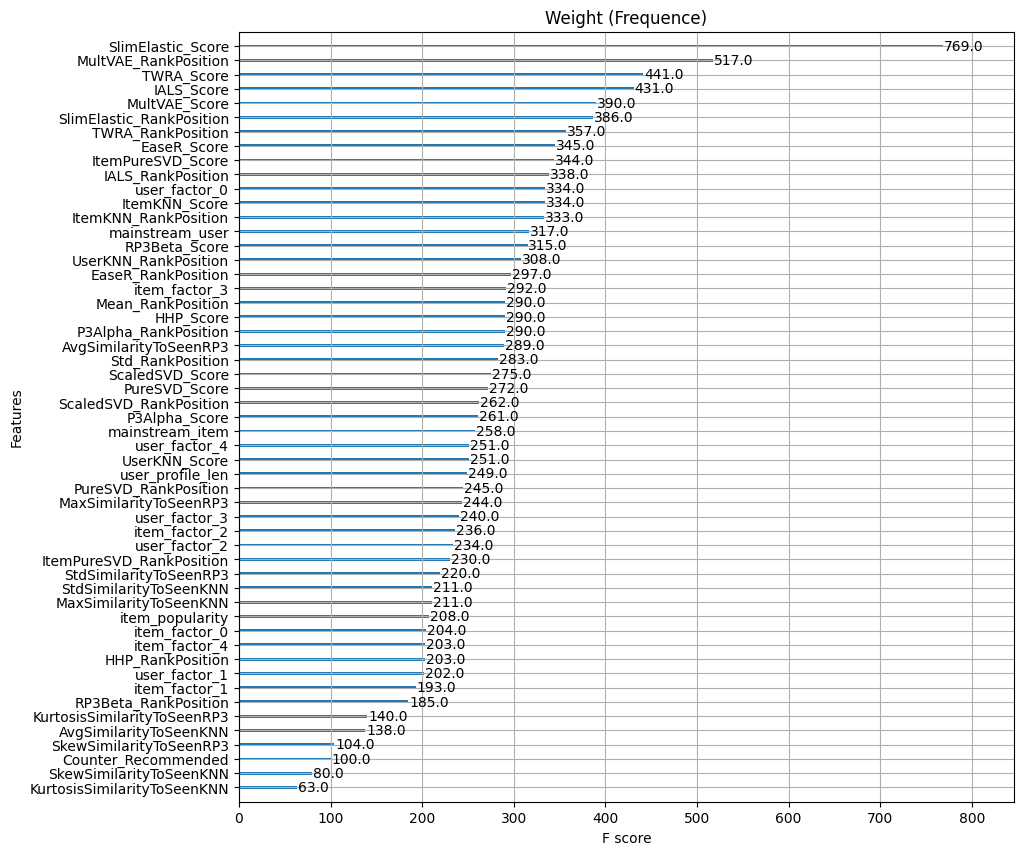

In [52]:
from xgboost import plot_importance

fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='weight', title='Weight (Frequence)', ax=ax)

<Axes: title={'center': 'Feature Importance (Cover)'}, xlabel='F score', ylabel='Features'>

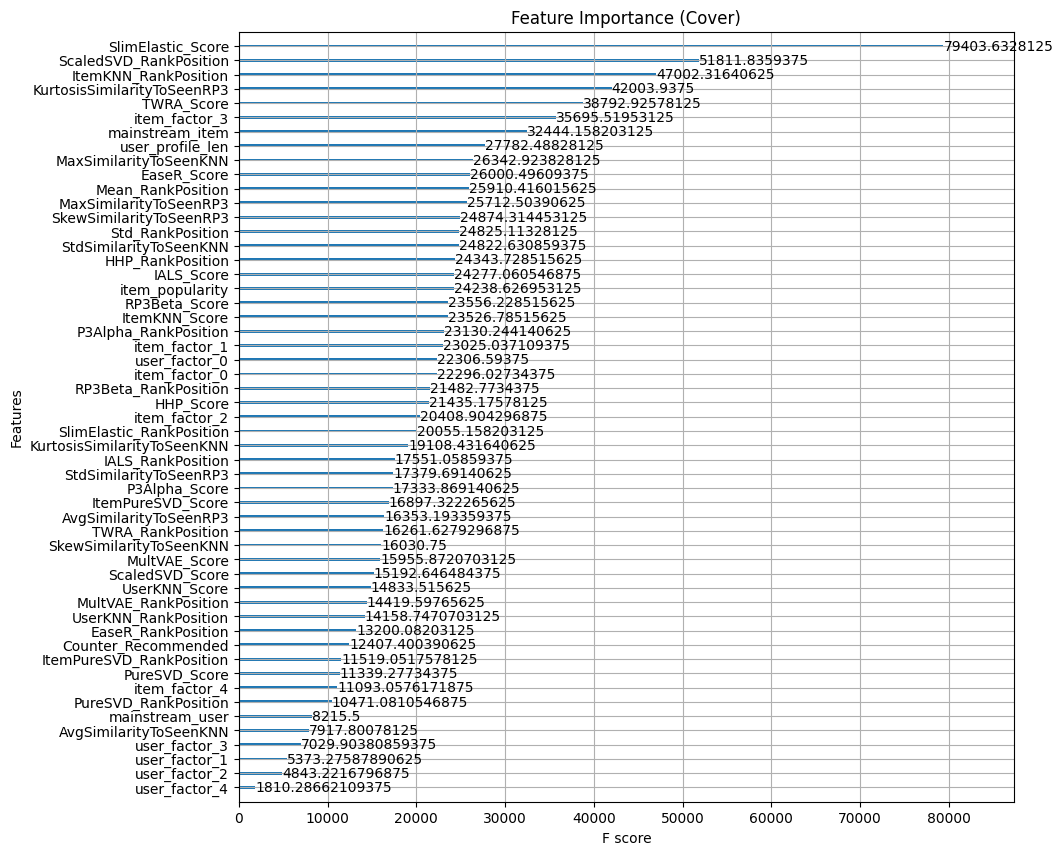

In [53]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='cover', title='Feature Importance (Cover)', ax=ax)

<Axes: title={'center': 'Feature Importance (Gain)'}, xlabel='F score', ylabel='Features'>

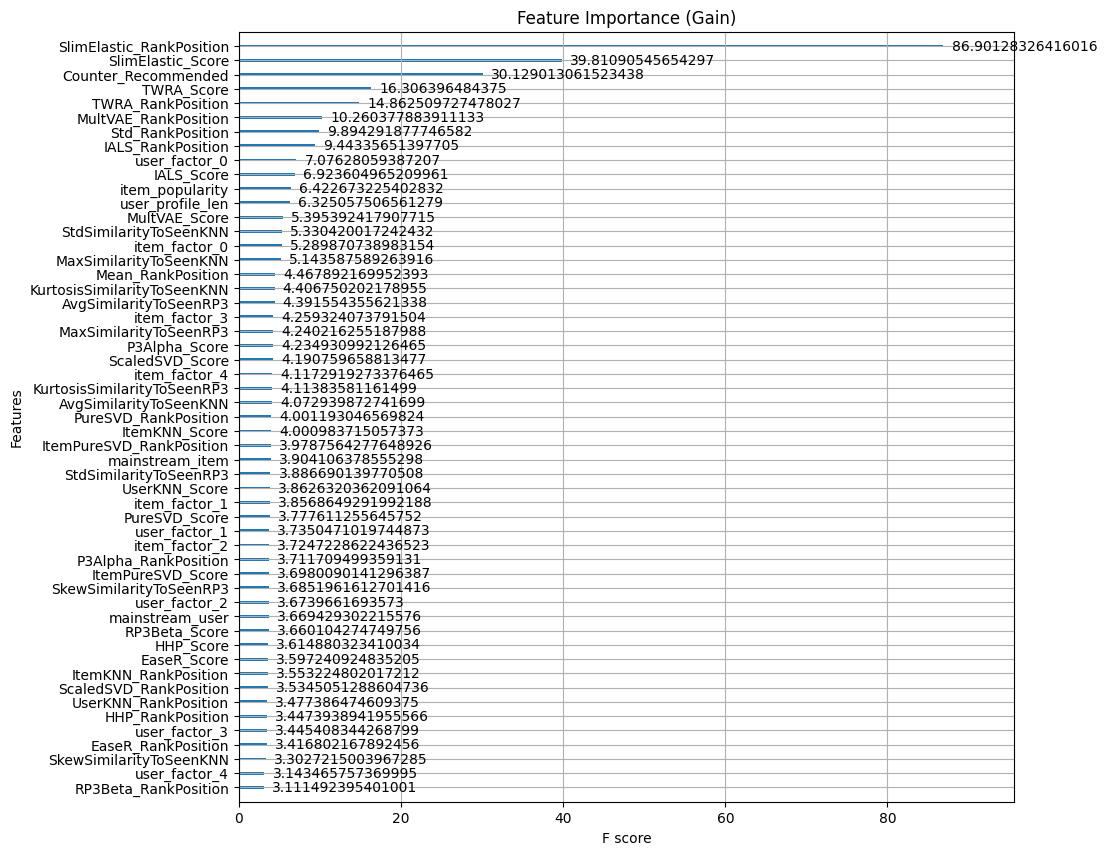

In [54]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='gain', title='Feature Importance (Gain)', ax=ax)

# PT 2

In [55]:
recommender_slim_r20 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train_complete)
recommender_slim_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'slim_elastic_train_validation.zip')

recommender_ials_r20 = IALSRecommender(URM_train_complete)
recommender_ials_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'ials_train_validation.zip')

recommender_lightfm_r20 = LightFMCFRecommender(URM_train_complete)
recommender_lightfm_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'lightfm_train_validation.zip')

recommender_multvae_r20 = MultVAERecommender_PyTorch(URM_train_complete)
recommender_multvae_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'mult_vae_train_validation.zip')

recommender_ease_r20 = EASE_R_Recommender(URM_train_complete)
recommender_ease_r20.fit(**params_ease_r)

recommender_itemknn_r20 = ItemKNNCFRecommender(URM_train_complete)
recommender_itemknn_r20.fit(**params_itemknn)

recommender_userknn_r20 = UserKNNCFRecommender(URM_train_complete)
recommender_userknn_r20.fit(**params_userknn)

recommender_p3alpha_r20 = P3alphaRecommender(URM_train_complete)
recommender_p3alpha_r20.fit(**params_p3alpha)

recommender_rp3_r20 = RP3betaRecommender(URM_train_complete)
recommender_rp3_r20.fit(**params_rp3beta)

recommender_pure_svd_r20 = PureSVDRecommender(URM_train_complete)
recommender_pure_svd_r20.fit(**params_pure_svd)

recommender_pure_svd_item_r20 = PureSVDItemRecommender(URM_train_complete)
recommender_pure_svd_item_r20.fit(**params_pure_svd_item)

recommender_scaled_svd_r20 = ScaledPureSVDRecommender(URM_train_complete)
recommender_scaled_svd_r20.fit(**params_scaled_svd)
user_factors_train = recommender_scaled_svd_r20.USER_factors
item_factors_train = recommender_scaled_svd_r20.ITEM_factors

recommender_hhp_r20 = HHPRecommender(URM_train_complete)
recommender_hhp_r20.fit(**params_hhp)

recommender_twra_r20 = TwoWayRankAggregationRecommender(URM_train_complete)
recommender_twra_r20.fit(**params_twra)

# --- Candidate Generators ---

recommender_slim_r50 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train_complete)
recommender_slim_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'slim_elastic_train_validation.zip')

recommender_ials_r50 = IALSRecommender(URM_train_complete)
recommender_ials_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'ials_train_validation.zip')

recommender_itemknn_r50 = ItemKNNCFRecommender(URM_train_complete)
recommender_itemknn_r50.fit(**params_itemknn_r50)

recommender_ease_r50 = EASE_R_Recommender(URM_train_complete)
recommender_ease_r50.fit(**params_ease_r50)

SLIMElasticNetRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/slim_elastic_train_validation.zip'
SLIMElasticNetRecommender: Loading complete
IALSRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/ials_train_validation.zip'
IALSRecommender: Loading complete
LightFMCFRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/lightfm_train_validation.zip'
LightFMCFRecommender: Loading complete
EASE_R_Recommender: Fitting model... 
EASE_R_Recommender: Fitting model... done in 19.01 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 6969 (100.0%), 555.22 column/sec. Elapsed time 12.55 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 27095 (100.0%), 532.36 column/sec. Elapsed time 50.90 sec
P3alphaRecommender: Similarity column 6969 (100.0%), 1306.28 column/sec. Elapsed time 5.34 sec
RP3betaRecommender: Si

In [56]:
recommender_object_dict = {
    'ItemKNN': recommender_itemknn_r20,
    'UserKNN': recommender_userknn_r20,
    'P3Alpha': recommender_p3alpha_r20,
    'RP3Beta': recommender_rp3_r20,
    #'NMF': recommender_nmf,
    'PureSVD': recommender_pure_svd_r20,
    'ScaledSVD': recommender_scaled_svd_r20,
    'ItemPureSVD': recommender_pure_svd_item_r20,
    'SlimElastic': recommender_slim_r20,
    #'SlimBPR': recommender_slim_bpr,
    'EaseR': recommender_ease_r20,
    'IALS': recommender_ials_r20,
    'MultVAE': recommender_multvae_r20,
    'HHP': recommender_hhp_r20,
    'TWRA': recommender_twra_r20,
    #'ALS': recommender_als,
    #'LightFM': recommender_lightfm_r20
}

In [57]:
cutoff = 50
n_users, n_items = URM_train_complete.shape

validation_dataframe = pd.DataFrame(index=range(0, n_users), columns = ["ItemID"])
validation_dataframe.index.name='UserID'

recommender_top_pop = TopPop(URM_train_complete)
recommender_top_pop.fit()

for user_id in tqdm.auto.tqdm(range(n_users)):
    recommendations_slim = recommender_slim_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ials = recommender_ials_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ease = recommender_ease_r50.recommend(user_id, cutoff=cutoff)
    recommendations_pop = recommender_top_pop.recommend(user_id, cutoff=20)
    
    recommendations = np.union1d(recommendations_slim, 
                        np.union1d(recommendations_ials, 
                        np.union1d(recommendations_ease, recommendations_pop)))
    validation_dataframe.loc[user_id, "ItemID"] = recommendations

validation_dataframe = validation_dataframe.explode("ItemID")

for label, recommender in tqdm.auto.tqdm(recommender_object_dict.items()):
    scores = recommender._compute_item_score(np.arange(n_users))
    linf_scores = scores / (LA.norm(scores, np.inf, axis=1, keepdims=True) + 1e-6)
    
    for user_id in tqdm.auto.tqdm(range(n_users)):
        item_list = validation_dataframe.loc[user_id, "ItemID"].values.astype(int)
        linf_scores[user_id, :] = recommender._remove_seen_on_scores(user_id, linf_scores[user_id, :])
        validation_dataframe.loc[user_id, f"{label}_Score"] = linf_scores[user_id, item_list]
        
        rank = np.argsort(linf_scores[user_id, :])[::-1]
        positions = np.zeros(n_items, dtype=int)
        positions[rank] = np.arange(n_items)
        validation_dataframe.loc[user_id, f"{label}_RankPosition"] = positions[item_list]
        
        recommended = np.isin(item_list, rank[:20], assume_unique=True) 
        validation_dataframe.loc[user_id, f"{label}_Recommended"] = recommended.astype(int)
    
    del scores, linf_scores, rank, positions, recommended
    gc.collect()

if 'ItemKNN' in recommender_object_dict:
    recommender_item = recommender_object_dict['ItemKNN']
    item_item_S = recommender_item.W_sparse.toarray()
    
    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train_complete[user_id].nonzero()[1]
        if len(seen_items) == 0:
            validation_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = 0
            validation_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = 0
            validation_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = 0
            validation_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = 0
            validation_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = 0
            validation_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = 0
        else:
            current_items = validation_dataframe.loc[user_id, "ItemID"].values.astype(int)
            similarities = item_item_S[current_items, :][:, seen_items]
            validation_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = similarities.mean(axis=1).flatten()
            validation_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = similarities.max(axis=1).flatten()
            validation_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = similarities.min(axis=1).flatten()
            validation_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = similarities.std(axis=1).flatten()
            validation_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = stats.skew(similarities, axis=1)
            validation_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = stats.kurtosis(similarities, axis=1)

    del item_item_S
    gc.collect()

if 'RP3Beta' in recommender_object_dict:
    recommender_rp3 = recommender_object_dict['RP3Beta']
    item_item_S = recommender_rp3.W_sparse.toarray()

    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train_complete[user_id].nonzero()[1] 
        if len(seen_items) == 0:
            validation_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = 0
            validation_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = 0
            validation_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = 0
            validation_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = 0
            validation_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = 0
            validation_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = 0
        else:
            current_items = validation_dataframe.loc[user_id, "ItemID"].values.astype(int)
            similarities = item_item_S[current_items, :][:, seen_items]
            validation_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = similarities.mean(axis=1).flatten()
            validation_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = similarities.max(axis=1).flatten()
            validation_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = similarities.min(axis=1).flatten()
            validation_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = similarities.std(axis=1).flatten()
            validation_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = stats.skew(similarities, axis=1)
            validation_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = stats.kurtosis(similarities, axis=1)

    del item_item_S
    gc.collect()
    
validation_dataframe = validation_dataframe.reset_index()
validation_dataframe = validation_dataframe.rename(columns = {"index": "UserID"})

recommended_columns = [col for col in validation_dataframe.columns if col.endswith('_Recommended')]
validation_dataframe['Counter_Recommended'] = validation_dataframe[recommended_columns].sum(axis=1).astype(int)

position_columns = [col for col in validation_dataframe.columns if col.endswith('_RankPosition')]
validation_dataframe['Mean_RankPosition'] = validation_dataframe[position_columns].mean(axis=1)
validation_dataframe['Std_RankPosition'] = validation_dataframe[position_columns].std(axis=1)

item_popularity = np.ediff1d(sps.csc_matrix(URM_train_complete).indptr)
item_popularity = item_popularity / np.max(item_popularity)
validation_dataframe['item_popularity'] = item_popularity[validation_dataframe["ItemID"].values.astype(int)]

user_popularity = np.ediff1d(sps.csr_matrix(URM_train_complete).indptr)
user_popularity = user_popularity / np.max(user_popularity)
validation_dataframe['user_profile_len'] = user_popularity[validation_dataframe["UserID"].values.astype(int)]

validation_dataframe.fillna(0, inplace=True)

validation_dataframe

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

...

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

,UserID,ItemID,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,P3Alpha_RankPosition,...,MaxSimilarityToSeenRP3,MinSimilarityToSeenRP3,StdSimilarityToSeenRP3,SkewSimilarityToSeenRP3,KurtosisSimilarityToSeenRP3,Counter_Recommended,Mean_RankPosition,Std_RankPosition,item_popularity,user_profile_len
0,0,76,0.000000,2448.0,0.0,0.091730,224.0,0.0,0.085595,133.0,...,0.070599,0.0,0.009333,6.459370,41.807209,0,344.846154,638.488429,0.071894,0.017064
1,0,275,0.222471,17.0,1.0,0.231199,36.0,0.0,0.192975,28.0,...,0.032407,0.0,0.005632,4.817671,21.732061,1,88.384615,63.285778,0.101937,0.017064
2,0,325,0.136026,43.0,0.0,0.000000,3053.0,0.0,0.072142,181.0,...,0.081131,0.0,0.009768,7.588007,58.057423,0,572.923077,859.532379,0.071705,0.017064
3,0,333,0.166594,29.0,0.0,0.173940,76.0,0.0,0.098187,110.0,...,0.078076,0.0,0.013860,4.234687,18.053015,1,147.461538,201.553804,0.016627,0.017064
4,0,457,0.136784,42.0,0.0,0.153166,107.0,0.0,0.093357,118.0,...,0.042190,0.0,0.006462,5.834005,32.211254,5,39.384615,38.150008,0.652244,0.017064
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2222660,27094,6228,0.498313,3.0,1.0,0.252501,60.0,0.0,0.372519,10.0,...,0.081608,0.0,0.006611,8.987988,93.505196,6,48.230769,48.318654,0.061124,0.058439
2222661,27094,6624,0.000000,4481.0,0.0,0.061449,580.0,0.0,0.168615,63.0,...,0.044325,0.0,0.002798,15.716315,245.004074,0,1842.384615,2040.923138,0.548701,0.058439
2222662,27094,6637,0.152156,84.0,0.0,0.319558,40.0,0.0,0.306243,26.0,...,0.030147,0.0,0.002838,9.264441,85.455521,1,81.000000,68.044103,0.074445,0.058439
2222663,27094,6643,0.191912,59.0,0.0,0.210339,84.0,0.0,0.170484,61.0,...,0.040803,0.0,0.004845,6.460589,40.956001,0,99.538462,68.610756,0.077279,0.058439


In [58]:
mainstream_user = URM_train_complete.dot(item_popularity) / np.where(user_popularity == 0, 1, user_popularity)
validation_dataframe['mainstream_user'] = mainstream_user[validation_dataframe["UserID"].values.astype(int)]

mainstream_item = URM_train_complete.T.dot(user_popularity) / np.where(item_popularity == 0, 1, item_popularity)
validation_dataframe['mainstream_item'] = mainstream_item[validation_dataframe["ItemID"].values.astype(int)]

user_factors_df = pd.DataFrame(user_factors_train[:, :5], columns=[f'user_factor_{i}' for i in range(user_factors_train[:, :5].shape[1])])
item_factors_df = pd.DataFrame(item_factors_train[:, :5], columns=[f'item_factor_{i}' for i in range(item_factors_train[:, :5].shape[1])])
validation_dataframe = validation_dataframe.merge(item_factors_df, left_on='ItemID', right_index=True)
validation_dataframe = validation_dataframe.merge(user_factors_df, left_on='UserID', right_index=True)
validation_dataframe = validation_dataframe.sort_values(by='UserID')

validation_dataframe

,UserID,ItemID,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,P3Alpha_RankPosition,...,item_factor_0,item_factor_1,item_factor_2,item_factor_3,item_factor_4,user_factor_0,user_factor_1,user_factor_2,user_factor_3,user_factor_4
0,0,76,0.000000,2448.0,0.0,0.091730,224.0,0.0,0.085595,133.0,...,0.014418,0.001334,-0.026160,0.013015,-0.013956,0.001293,0.000234,-0.003879,0.000453,0.000302
67,0,5407,0.000000,4160.0,0.0,0.491806,8.0,1.0,0.295504,8.0,...,0.025201,-0.007021,-0.055164,-0.006976,0.011933,0.001293,0.000234,-0.003879,0.000453,0.000302
66,0,5252,0.000000,4146.0,0.0,0.029117,901.0,0.0,0.000000,4090.0,...,0.051919,-0.039060,0.038623,-0.071175,0.054958,0.001293,0.000234,-0.003879,0.000453,0.000302
64,0,5076,0.000000,6326.0,0.0,0.027402,1006.0,0.0,0.000000,6426.0,...,0.058109,-0.050121,-0.008250,-0.052616,0.008035,0.001293,0.000234,-0.003879,0.000453,0.000302
63,0,4877,0.154272,33.0,0.0,0.184259,64.0,0.0,0.174361,37.0,...,0.060770,-0.034185,-0.026273,-0.004869,0.041460,0.001293,0.000234,-0.003879,0.000453,0.000302
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2222601,27094,1983,0.203843,54.0,0.0,0.220244,77.0,0.0,0.127295,105.0,...,0.037266,-0.000700,-0.038945,-0.007418,-0.011943,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222599,27094,1522,0.118560,124.0,0.0,0.431801,13.0,1.0,0.343630,18.0,...,0.014487,0.018335,-0.025972,-0.009630,-0.004130,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222598,27094,1489,0.254113,34.0,0.0,0.289056,48.0,0.0,0.154627,70.0,...,0.011727,0.020749,-0.023463,-0.007069,-0.003988,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222619,27094,3410,0.000000,5819.0,0.0,0.113713,264.0,0.0,0.085360,194.0,...,0.068900,-0.053081,0.020628,-0.054912,0.082360,0.005813,0.007368,-0.020213,-0.003414,-0.000575


In [59]:
# validation_dataframe["UserID"] = validation_dataframe["UserID"].astype("category")
# validation_dataframe["ItemID"] = validation_dataframe["ItemID"].astype("category")

validation_dataframe["UserID"] = validation_dataframe["UserID"].astype(int)
validation_dataframe["ItemID"] = validation_dataframe["ItemID"].astype(int)

# object_columns = validation_dataframe.select_dtypes(include=['object']).columns
# validation_dataframe[object_columns] = validation_dataframe[object_columns].astype('category')

In [60]:
class XGBoostRerankerRecommender:
    def __init__(self, URM_train, XGB_model, df):
        self.URM_train = URM_train
        self.XGB_model = XGB_model
        
        self.df = df.set_index("UserID").sort_index()
        
    def recommend(self, user_ids, cutoff=10, return_scores=True, remove_seen_flag=True, remove_top_pop_flag=True, remove_custom_items_flag=False):
        recommendations = []
        scores_batch = []
        
        for user_id in user_ids:
            if user_id in self.df.index:
                user_rows = self.df.loc[user_id]
                
                if isinstance(user_rows, pd.Series):
                    user_rows = user_rows.to_frame().T
                
                items_to_rank = user_rows["ItemID"].values
    
                X_test = user_rows.drop(columns=["ItemID"]) 
                xgb_scores = self.XGB_model.predict(X_test)
                top_indices = np.argsort(xgb_scores)[-cutoff:][::-1]
                
                user_recs = items_to_rank[top_indices].tolist()
                best_scores = xgb_scores[top_indices]
            else:
                # User has no candidates in the dataframe (shouldn't happen with TopPop)
                user_recs = []
                best_scores = []

            recommendations.append(user_recs)
            
            if return_scores:
                user_scores_row = np.full(self.URM_train.shape[1], -np.inf)
                for rank, (item_idx, score) in enumerate(zip(user_recs, best_scores)):
                    user_scores_row[item_idx] = score 
                
                scores_batch.append(user_scores_row)

        if return_scores:
            return np.array(recommendations), np.array(scores_batch)
            
        return np.array(recommendations)

    def get_URM_train(self):
        return self.URM_train

In [61]:
recommender = XGBoostRerankerRecommender(URM_train_complete, XGB_model, validation_dataframe)
result_df, _ = evaluator.evaluateRecommender(recommender)
result_df

EvaluatorHoldout: Processed 27067 (100.0%) in 3.78 min. Users per second: 119


,PRECISION,PRECISION_RECALL_MIN_DEN,RECALL,MAP,MAP_MIN_DEN,MRR,NDCG,F1,HIT_RATE,ARHR_ALL_HITS,...,COVERAGE_USER,COVERAGE_USER_HIT,USERS_IN_GT,DIVERSITY_GINI,SHANNON_ENTROPY,RATIO_DIVERSITY_HERFINDAHL,RATIO_DIVERSITY_GINI,RATIO_SHANNON_ENTROPY,RATIO_AVERAGE_POPULARITY,RATIO_NOVELTY
cutoff,,,,,,,,,,,,,,,,,,,,,
20,0.228149,0.350405,0.294831,0.104946,0.154521,0.519992,0.321099,0.257239,0.963646,0.981562,...,0.998967,0.96265,0.998967,0.07407,9.244461,0.99711,0.273873,0.824533,1.535852,0.197083


In [62]:
def objective_xgboost(trial):

    XGB_model = XGBRanker(
        objective = trial.suggest_categorical('objective', ["rank:map", "rank:pairwise", "rank:ndcg"]),
        n_estimators = trial.suggest_int('n_estimators', 10, 5000, log=True),
        learning_rate = trial.suggest_float('learning_rate', 1e-4, 0.5, log=True),
        reg_alpha = trial.suggest_float('reg_alpha', 1e-5, 1, log=True),
        reg_lambda = trial.suggest_float('reg_lambda', 1e-5, 1, log=True),
        max_depth = trial.suggest_int('max_depth', 3, 20),
        max_leaves = trial.suggest_int('max_leaves', 8, 1024),
        grow_policy = trial.suggest_categorical('grow_policy', ['depthwise', 'lossguide']),
        verbosity = 2,
        booster = 'gbtree',
        # tree_method = trial.suggest_categorical('tree_method', ['exact', 'approx', 'hist']),
        tree_method = 'hist',
        gamma = trial.suggest_float('gamma', 1e-7, 10, log=True),
        min_child_weight = trial.suggest_float('min_child_weight', 1e-7, 1, log=True),
        subsample = trial.suggest_float('subsample', 0.1, 0.9),
        colsample_bytree = trial.suggest_float('colsample_bytree', 0.1, 0.9),
        # enable_categorical = True
    )
    
    XGB_model.fit(
        X_train,
        y_train,
        group=groups,
        verbose=True
    )
    
    recommender = XGBoostRerankerRecommender(URM_train_complete, XGB_model, validation_dataframe)
    result_df, _ = evaluator.evaluateRecommender(recommender)
        
    return result_df.loc[20, 'RECALL']

In [63]:
try:
    shutil.copyfile(
        f'/kaggle/working/RecSys_challenge_2025/tuning_results/xgboost/{config["database_name"]}', 
        config['database_path']
    )
except FileNotFoundError:
    pass # if not present optuna will create it

In [64]:
try:
    shutil.copyfile(
        f"tuning_results/xgboost/best_params/{config['json_name']}", 
        f"/kaggle/working/{config['json_name']}"
    )
except FileNotFoundError:
    pass # if not present optuna will create it

In [65]:
if config['tune_parameters']:
    study = optuna.create_study(direction='maximize', study_name='xgboost_tuning', 
                                storage=f'sqlite:///{config["database_path"]}', load_if_exists=True)
    study.optimize(objective_xgboost, n_trials=config['n_trials'], timeout=34200)

[I 2026-01-06 23:15:13,950] Using an existing study with name 'xgboost_tuning' instead of creating a new one.


EvaluatorHoldout: Processed 27067 (100.0%) in 3.73 min. Users per second: 121


[I 2026-01-06 23:20:49,866] Trial 82 finished with value: 0.29375687405422796 and parameters: {'objective': 'rank:pairwise', 'n_estimators': 122, 'learning_rate': 0.0029213599867540306, 'reg_alpha': 0.013783633074817862, 'reg_lambda': 0.38515141125554386, 'max_depth': 12, 'max_leaves': 45, 'grow_policy': 'lossguide', 'gamma': 6.074072073463148e-07, 'min_child_weight': 8.772930620296608e-07, 'subsample': 0.6550954953198646, 'colsample_bytree': 0.49218735106444444}. Best is trial 63 with value: 0.29660460410578177.


In [66]:
if config['save_github'] and config['tune_parameters']:
    upload_file(
        config['database_path'], 
        f'tuning_results/xgboost/{config["database_name"]}',
        'Tuning db updated results (from kaggle notebook)'
    )

    if config['save_json']:
        j_name = config['json_name']
        l_path = f"/kaggle/working/{j_name}"
        r_path = f"tuning_results/xgboost/best_params/{j_name}"
        
        best_val, best_params, best_trial_num, best_study_name = -float('inf'), {}, None, None
        
        try:
            for s in optuna.get_all_study_summaries(storage=f"sqlite:///{config['database_path']}"):
                if s.best_trial and s.best_trial.value > best_val:
                    best_val, best_params, best_trial_num, best_study_name = s.best_trial.value, s.best_trial.params, s.best_trial.number, s.study_name
        except:
            best_val, best_params, best_trial_num, best_study_name = study.best_value, study.best_params, study.best_trial.number, study.study_name
        
        prev_val, exists = -float('inf'), False
        try:
            prev_val = json.loads(repo.get_contents(r_path).decoded_content.decode()).get('value', -float('inf'))
            exists = True
        except:
            pass
    
        if not exists or best_val > prev_val:
            print(f"Updating JSON. Best: {best_val:.6f} (Prev: {prev_val:.6f})")
            with open(l_path, 'w') as f:
                json.dump({"value": best_val, "study_name": best_study_name, "trial_number": best_trial_num, "params": best_params}, f, indent=4)
            if config.get('save_github'):
                upload_file(l_path, r_path, f'Update params {j_name} (from kaggle notebook)')
        else:
            print(f"No update needed. Best: {best_val:.6f} <= Saved: {prev_val:.6f}")

No update needed. Best: 0.296605 <= Saved: 0.296605


In [67]:
with open(f"/kaggle/working/{j_name}", 'r') as params_file:
    xgboost_params = json.load(params_file)["params"]
xgboost_params['tree_method'] = 'hist'
xgboost_params['booster'] = 'gbtree'
xgboost_params

{'objective': 'rank:map',
 'n_estimators': 4371,
 'learning_rate': 0.003457658018185236,
 'reg_alpha': 0.0011610351040273333,
 'reg_lambda': 0.6767343977730601,
 'max_depth': 10,
 'max_leaves': 337,
 'grow_policy': 'lossguide',
 'gamma': 4.1407149851506526e-07,
 'min_child_weight': 6.62808266225427e-06,
 'subsample': 0.7075929830173355,
 'colsample_bytree': 0.44496570945018943,
 'tree_method': 'hist',
 'booster': 'gbtree'}

In [68]:
recommender_itemknn_r20 = ItemKNNCFRecommender(URM_train_complete)
recommender_itemknn_r20.fit(**params_itemknn)

recommender_userknn_r20 = UserKNNCFRecommender(URM_train_complete)
recommender_userknn_r20.fit(**params_userknn)

recommender_rp3_r20 = RP3betaRecommender(URM_train_complete)
recommender_rp3_r20.fit(**params_rp3beta)

recommender_p3alpha_r20 = P3alphaRecommender(URM_train_complete)
recommender_p3alpha_r20.fit(**params_p3alpha)

recommender_pure_svd_r20 = PureSVDRecommender(URM_train_complete)
recommender_pure_svd_r20.fit(**params_pure_svd)

recommender_pure_svd_item_r20 = PureSVDItemRecommender(URM_train_complete)
recommender_pure_svd_item_r20.fit(**params_pure_svd_item)

recommender_scaled_svd_r20 = ScaledPureSVDRecommender(URM_train_complete)
recommender_scaled_svd_r20.fit(**params_scaled_svd)
user_factors_final_train = recommender_scaled_svd_r20.USER_factors
item_factors_final_train = recommender_scaled_svd_r20.ITEM_factors

recommender_slim_r20 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train_complete)
recommender_slim_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'slim_elastic_train_validation.zip')

recommender_ials_r20 = IALSRecommender(URM_train_complete)
recommender_ials_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'ials_train_validation.zip')

recommender_multvae_r20 = MultVAERecommender_PyTorch(URM_train_complete)
recommender_multvae_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'mult_vae_train_validation.zip')

recommender_lightfm_r20 = LightFMCFRecommender(URM_train_complete)
recommender_lightfm_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'lightfm_train_validation.zip')

recommender_ease_r20 = EASE_R_Recommender(URM_train_complete)
recommender_ease_r20.fit(**params_ease_r)

recommender_hhp_r20 = HHPRecommender(URM_train_complete)
recommender_hhp_r20.fit(**params_hhp)

recommender_twra_r20 = TwoWayRankAggregationRecommender(URM_train_complete)
recommender_twra_r20.fit(**params_twra)

# --- Candidate Generators ---

recommender_slim_r50 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_train_complete)
recommender_slim_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'slim_elastic_train_validation.zip')

recommender_ials_r50 = IALSRecommender(URM_train_complete)
recommender_ials_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'ials_train_validation.zip')

recommender_itemknn_r50 = ItemKNNCFRecommender(URM_train_complete)
recommender_itemknn_r50.fit(**params_itemknn_r50)

recommender_ease_r50 = EASE_R_Recommender(URM_train_complete)
recommender_ease_r50.fit(**params_ease_r50)

Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 6969 (100.0%), 659.85 column/sec. Elapsed time 10.56 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 27095 (100.0%), 547.89 column/sec. Elapsed time 49.45 sec
RP3betaRecommender: Similarity column 6969 (100.0%), 1683.15 column/sec. Elapsed time 4.14 sec
P3alphaRecommender: Similarity column 6969 (100.0%), 1298.68 column/sec. Elapsed time 5.37 sec
PureSVDRecommender: Computing SVD decomposition...
PureSVDRecommender: Computing SVD decomposition... done in 1.09 sec
PureSVDItemRecommender: Computing SVD decomposition...
PureSVDItemRecommender: Computing SVD decomposition... Done!
ScaledPureSVDRecommender: Computing SVD decomposition...
ScaledPureSVDRecommender: Computing SVD decomposition... done in 4.02 sec
SLIMElasticNetRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/slim_elastic_train_validation.zip'
SLIMElasticNetRecommender: 

In [69]:
recommender_object_dict = {
    'ItemKNN': recommender_itemknn_r20,
    'UserKNN': recommender_userknn_r20,
    'P3Alpha': recommender_p3alpha_r20,
    'RP3Beta': recommender_rp3_r20,
    #'NMF': recommender_nmf,
    'PureSVD': recommender_pure_svd_r20,
    'ScaledSVD': recommender_scaled_svd_r20,
    'ItemPureSVD': recommender_pure_svd_item_r20,
    'SlimElastic': recommender_slim_r20,
    #'SlimBPR': recommender_slim_bpr,
    'EaseR': recommender_ease_r20,
    'IALS': recommender_ials_r20,
    'MultVAE': recommender_multvae_r20,
    'HHP': recommender_hhp_r20,
    'TWRA': recommender_twra_r20,
    #'ALS': recommender_als,
    #'LightFM': recommender_lightfm_r20
}

In [70]:
cutoff = 50
n_users, n_items = URM_train_complete.shape
final_train_dataframe = pd.DataFrame(index=range(0, n_users), columns = ["ItemID"])
final_train_dataframe.index.name='UserID'

recommender_top_pop = TopPop(URM_train_complete)
recommender_top_pop.fit()

for user_id in tqdm.auto.tqdm(range(n_users)):
    recommendations_slim = recommender_slim_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ials = recommender_ials_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ease = recommender_ease_r50.recommend(user_id, cutoff=cutoff)
    recommendations_pop = recommender_top_pop.recommend(user_id, cutoff=20)
    
    recommendations = np.union1d(recommendations_slim, 
                        np.union1d(recommendations_ials, 
                        np.union1d(recommendations_ease, recommendations_pop)))
    final_train_dataframe.loc[user_id, "ItemID"] = recommendations

final_train_dataframe = final_train_dataframe.explode("ItemID")

URM_test_complete_coo = sps.coo_matrix(URM_test_complete)
correct_recommendations = pd.DataFrame({"UserID": URM_test_complete_coo.row,
                                        "ItemID": URM_test_complete_coo.col})

final_train_dataframe = pd.merge(final_train_dataframe, correct_recommendations, on=['UserID','ItemID'], how='left', indicator='Exist')
final_train_dataframe["Label"] = final_train_dataframe["Exist"] == "both"
final_train_dataframe.drop(columns = ['Exist'], inplace=True)

final_train_dataframe = final_train_dataframe.set_index('UserID')

for label, recommender in tqdm.auto.tqdm(recommender_object_dict.items()):
    scores = recommender._compute_item_score(np.arange(n_users))
    linf_scores = scores / (LA.norm(scores, np.inf, axis=1, keepdims=True) + 1e-6)
    
    for user_id in tqdm.auto.tqdm(range(n_users), leave=False):
        item_list = final_train_dataframe.loc[user_id, "ItemID"]
        if isinstance(item_list, pd.Series):
             item_list = item_list.values
        item_list = np.array(item_list).flatten().astype(int)

        linf_scores[user_id, :] = recommender._remove_seen_on_scores(user_id, linf_scores[user_id, :])
        final_train_dataframe.loc[user_id, f"{label}_Score"] = linf_scores[user_id, item_list]
        
        rank = np.argsort(linf_scores[user_id, :])[::-1]
        positions = np.zeros(n_items, dtype=int)
        positions[rank] = np.arange(n_items)
        final_train_dataframe.loc[user_id, f"{label}_RankPosition"] = positions[item_list]
        
        recommended = np.isin(item_list, rank[:20], assume_unique=True)
        final_train_dataframe.loc[user_id, f"{label}_Recommended"] = recommended.astype(int)
    
    del scores, linf_scores, rank, positions, recommended
    gc.collect()

if 'ItemKNN' in recommender_object_dict:
    item_item_S = recommender_itemknn_r20.W_sparse.toarray()
    
    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train_complete[user_id].nonzero()[1]
        
        try:
             current_items = final_train_dataframe.loc[user_id, "ItemID"]
             if isinstance(current_items, pd.Series):
                 current_items = current_items.values
             current_items = np.array(current_items).flatten().astype(int)
        except KeyError:
             current_items = np.array([])

        if len(seen_items) == 0 or len(current_items) == 0:
            final_train_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = 0
            final_train_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = 0
            final_train_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = 0
            final_train_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = 0
            final_train_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = 0
            final_train_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = 0
        else:
            similarities = item_item_S[current_items, :][:, seen_items]
            final_train_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = similarities.mean(axis=1).flatten()
            final_train_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = similarities.max(axis=1).flatten()
            final_train_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = similarities.min(axis=1).flatten()
            final_train_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = similarities.std(axis=1).flatten()
            final_train_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = stats.skew(similarities, axis=1)
            final_train_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = stats.kurtosis(similarities, axis=1)
    
    del item_item_S
    gc.collect()

if 'RP3Beta' in recommender_object_dict:
    item_item_S = recommender_rp3_r20.W_sparse.toarray()
    
    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train_complete[user_id].nonzero()[1]
        
        try:
             current_items = final_train_dataframe.loc[user_id, "ItemID"]
             if isinstance(current_items, pd.Series):
                 current_items = current_items.values
             current_items = np.array(current_items).flatten().astype(int)
        except KeyError:
             current_items = np.array([])

        if len(seen_items) == 0 or len(current_items) == 0:
            final_train_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = 0
            final_train_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = 0
            final_train_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = 0
            final_train_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = 0
            final_train_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = 0
            final_train_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = 0
        else:
            similarities = item_item_S[current_items, :][:, seen_items]
            final_train_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = similarities.mean(axis=1).flatten()
            final_train_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = similarities.max(axis=1).flatten()
            final_train_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = similarities.min(axis=1).flatten()
            final_train_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = similarities.std(axis=1).flatten()
            final_train_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = stats.skew(similarities, axis=1)
            final_train_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = stats.kurtosis(similarities, axis=1)

    del item_item_S
    gc.collect()

final_train_dataframe = final_train_dataframe.reset_index()
final_train_dataframe = final_train_dataframe.rename(columns = {"index": "UserID"})

recommended_columns = [col for col in final_train_dataframe.columns if col.endswith('_Recommended')]
final_train_dataframe['Counter_Recommended'] = final_train_dataframe[recommended_columns].sum(axis=1).astype(int)

position_columns = [col for col in final_train_dataframe.columns if col.endswith('_RankPosition')]
final_train_dataframe['Mean_RankPosition'] = final_train_dataframe[position_columns].mean(axis=1)
final_train_dataframe['Std_RankPosition'] = final_train_dataframe[position_columns].std(axis=1)

item_popularity = np.ediff1d(sps.csc_matrix(URM_train_complete).indptr)
item_popularity = item_popularity / np.max(item_popularity)
final_train_dataframe['item_popularity'] = item_popularity[final_train_dataframe["ItemID"].values.astype(int)]

user_popularity = np.ediff1d(sps.csr_matrix(URM_train_complete).indptr)
user_popularity = user_popularity / np.max(user_popularity)
final_train_dataframe['user_profile_len'] = user_popularity[final_train_dataframe["UserID"].values.astype(int)]

mainstream_user = URM_train_complete.dot(item_popularity) / np.where(user_popularity == 0, 1, user_popularity)
final_train_dataframe['mainstream_user'] = mainstream_user[final_train_dataframe["UserID"].values.astype(int)]

mainstream_item = URM_train_complete.T.dot(user_popularity) / np.where(item_popularity == 0, 1, item_popularity)
final_train_dataframe['mainstream_item'] = mainstream_item[final_train_dataframe["ItemID"].values.astype(int)]

user_factors_df = pd.DataFrame(user_factors_final_train[:, :5], columns=[f'user_factor_{i}' for i in range(user_factors_final_train[:, :5].shape[1])])
item_factors_df = pd.DataFrame(item_factors_final_train[:, :5], columns=[f'item_factor_{i}' for i in range(item_factors_final_train[:, :5].shape[1])])

final_train_dataframe = final_train_dataframe.merge(item_factors_df, left_on='ItemID', right_index=True)
final_train_dataframe = final_train_dataframe.merge(user_factors_df, left_on='UserID', right_index=True)
final_train_dataframe = final_train_dataframe.sort_values(by='UserID')

final_train_dataframe.fillna(0, inplace=True)

final_train_dataframe

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

...

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

,UserID,ItemID,Label,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,...,item_factor_0,item_factor_1,item_factor_2,item_factor_3,item_factor_4,user_factor_0,user_factor_1,user_factor_2,user_factor_3,user_factor_4
0,0,76,False,0.000000,2448.0,0.0,0.091730,224.0,0.0,0.085595,...,0.014418,0.001334,-0.026160,0.013015,-0.013956,0.001293,0.000234,-0.003879,0.000453,0.000302
67,0,5407,False,0.000000,4160.0,0.0,0.491806,8.0,1.0,0.295504,...,0.025201,-0.007021,-0.055164,-0.006976,0.011933,0.001293,0.000234,-0.003879,0.000453,0.000302
66,0,5252,False,0.000000,4146.0,0.0,0.029117,901.0,0.0,0.000000,...,0.051919,-0.039060,0.038623,-0.071175,0.054958,0.001293,0.000234,-0.003879,0.000453,0.000302
64,0,5076,False,0.000000,6326.0,0.0,0.027402,1006.0,0.0,0.000000,...,0.058109,-0.050121,-0.008250,-0.052616,0.008035,0.001293,0.000234,-0.003879,0.000453,0.000302
63,0,4877,False,0.154272,33.0,0.0,0.184259,64.0,0.0,0.174361,...,0.060770,-0.034185,-0.026273,-0.004869,0.041460,0.001293,0.000234,-0.003879,0.000453,0.000302
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2222601,27094,1983,False,0.203843,54.0,0.0,0.220244,77.0,0.0,0.127295,...,0.037266,-0.000700,-0.038945,-0.007418,-0.011943,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222599,27094,1522,True,0.118560,124.0,0.0,0.431801,13.0,1.0,0.343630,...,0.014487,0.018335,-0.025972,-0.009630,-0.004130,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222598,27094,1489,False,0.254113,34.0,0.0,0.289056,48.0,0.0,0.154627,...,0.011727,0.020749,-0.023463,-0.007069,-0.003988,0.005813,0.007368,-0.020213,-0.003414,-0.000575
2222619,27094,3410,False,0.000000,5819.0,0.0,0.113713,264.0,0.0,0.085360,...,0.068900,-0.053081,0.020628,-0.054912,0.082360,0.005813,0.007368,-0.020213,-0.003414,-0.000575


In [71]:
groups = final_train_dataframe.groupby("UserID").size().values
groups

array([91, 83, 94, ..., 75, 81, 88])

In [72]:
XGB_model = XGBRanker(**xgboost_params)

y_train = final_train_dataframe["Label"]
X_train = final_train_dataframe.drop(columns=["Label", "UserID", "ItemID"])

XGB_model.fit(
    X_train,
    y_train,
    group=groups,
    verbose=True
)

XGBRanker(base_score=None, booster='gbtree', callbacks=None,
          colsample_bylevel=None, colsample_bynode=None,
          colsample_bytree=0.44496570945018943, device=None,
          early_stopping_rounds=None, enable_categorical=False,
          eval_metric=None, feature_types=None, gamma=4.1407149851506526e-07,
          grow_policy='lossguide', importance_type=None,
          interaction_constraints=None, learning_rate=0.003457658018185236,
          max_bin=None, max_cat_threshold=None, max_cat_to_onehot=None,
          max_delta_step=None, max_depth=10, max_leaves=337,
          min_child_weight=6.62808266225427e-06, missing=nan,
          monotone_constraints=None, multi_strategy=None, n_estimators=4371,
          n_jobs=None, num_parallel_tree=None, objective='rank:map', ...)

<Axes: title={'center': 'Feature Importance (Weight)'}, xlabel='F score', ylabel='Features'>

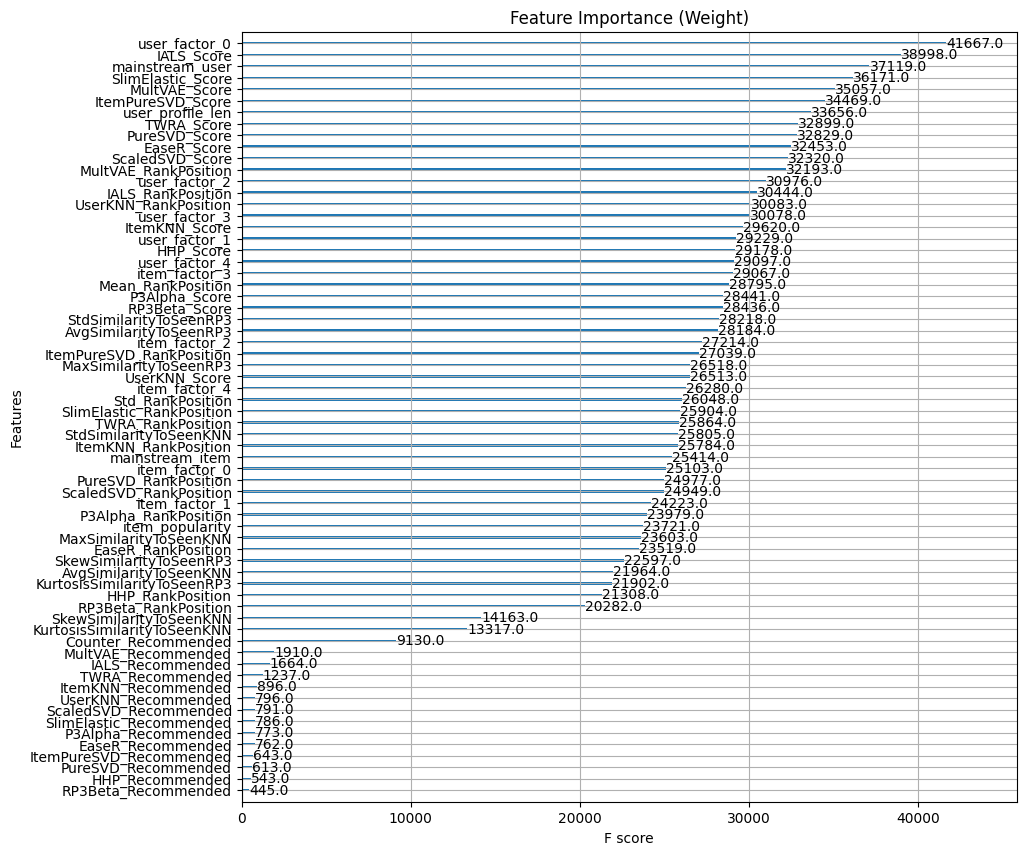

In [73]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='weight', title='Feature Importance (Weight)', ax=ax)

<Axes: title={'center': 'Feature Importance (Cover)'}, xlabel='F score', ylabel='Features'>

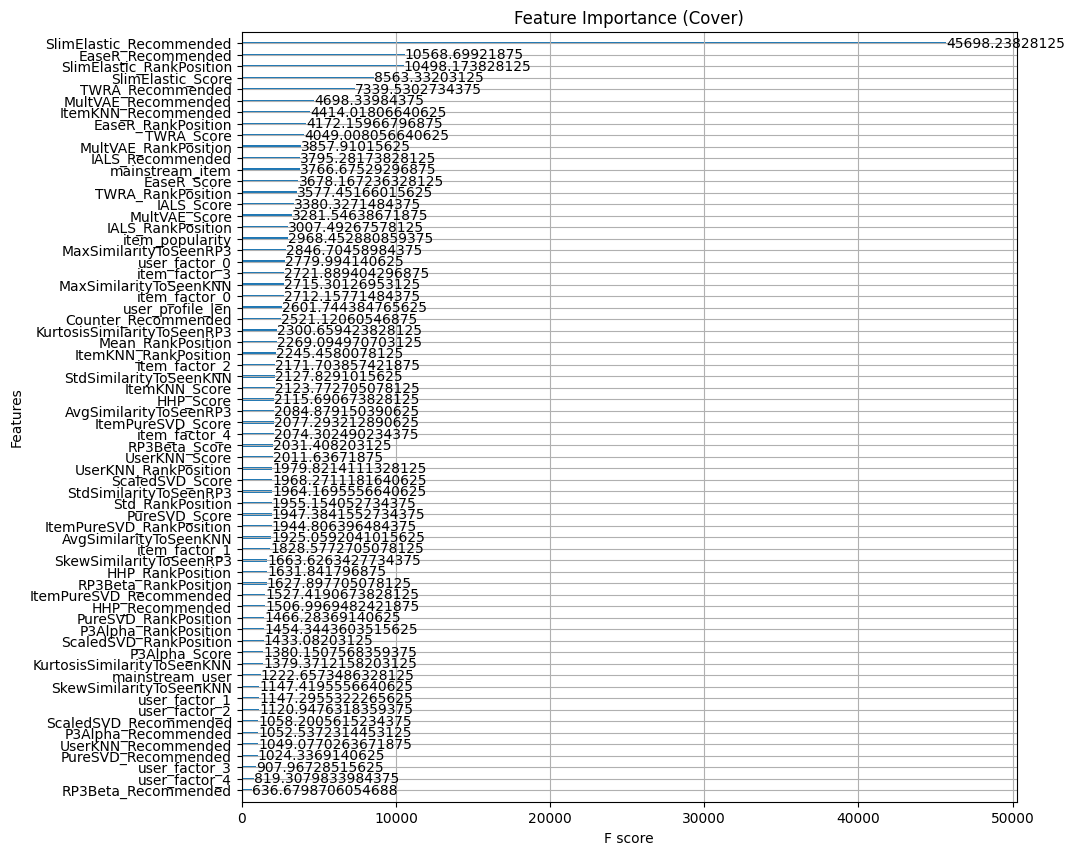

In [74]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='cover', title='Feature Importance (Cover)', ax=ax)

<Axes: title={'center': 'Feature Importance (Gain)'}, xlabel='F score', ylabel='Features'>

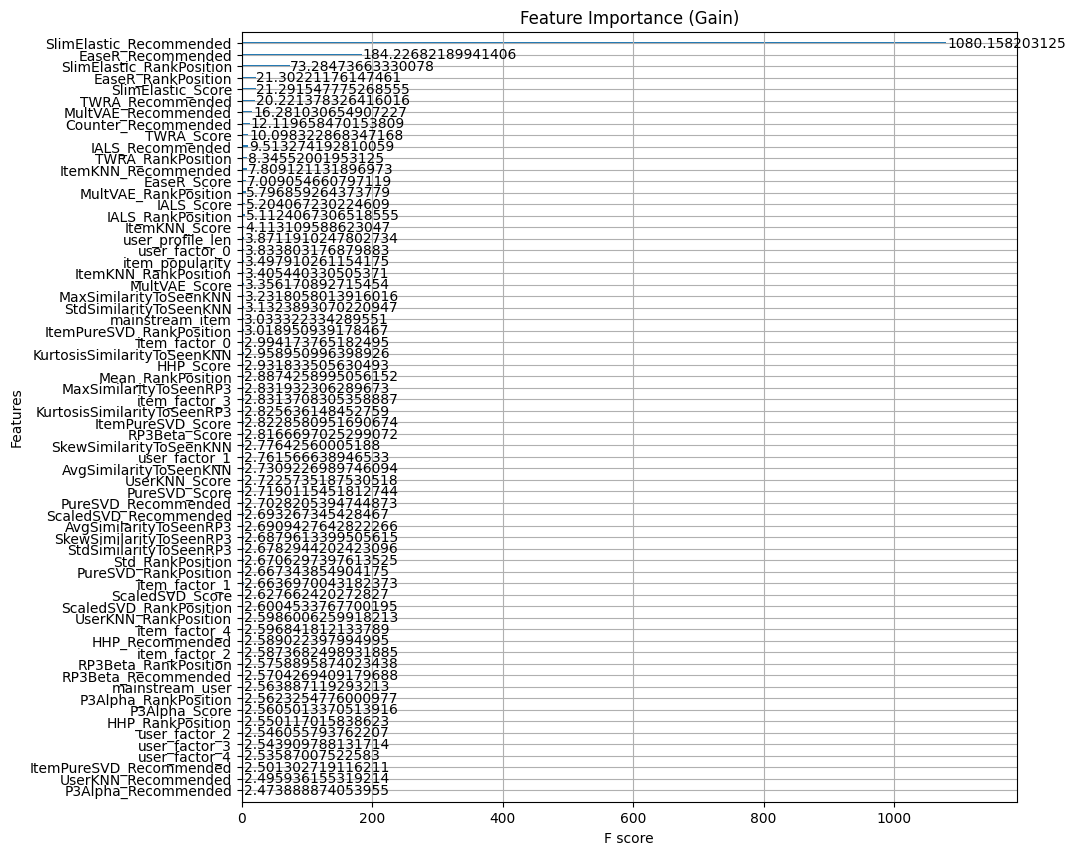

In [75]:
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
plot_importance(XGB_model, importance_type='gain', title='Feature Importance (Gain)', ax=ax)

# PT 3

In [76]:
recommender_itemknn_r20 = ItemKNNCFRecommender(URM_all)
recommender_itemknn_r20.fit(**params_itemknn)

recommender_userknn_r20 = UserKNNCFRecommender(URM_all)
recommender_userknn_r20.fit(**params_userknn)

recommender_rp3_r20 = RP3betaRecommender(URM_all)
recommender_rp3_r20.fit(**params_rp3beta)

recommender_p3alpha_r20 = P3alphaRecommender(URM_all)
recommender_p3alpha_r20.fit(**params_p3alpha)

recommender_pure_svd_r20 = PureSVDRecommender(URM_all)
recommender_pure_svd_r20.fit(**params_pure_svd)

recommender_pure_svd_item_r20 = PureSVDItemRecommender(URM_all)
recommender_pure_svd_item_r20.fit(**params_pure_svd_item)

recommender_scaled_svd_r20 = ScaledPureSVDRecommender(URM_all)
recommender_scaled_svd_r20.fit(**params_scaled_svd)
user_factors_final_train = recommender_scaled_svd_r20.USER_factors
item_factors_final_train = recommender_scaled_svd_r20.ITEM_factors

recommender_slim_r20 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_all)
recommender_slim_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'slim_elastic_all.zip')

recommender_ials_r20 = IALSRecommender(URM_all)
recommender_ials_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'ials_all.zip')

recommender_multvae_r20 = MultVAERecommender_PyTorch(URM_all)
recommender_multvae_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'mult_vae_all.zip')

recommender_lightfm_r20 = LightFMCFRecommender(URM_all)
recommender_lightfm_r20.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@20/', 'lightfm_all.zip')

recommender_ease_r20 = EASE_R_Recommender(URM_all)
recommender_ease_r20.fit(**params_ease_r)

recommender_hhp_r20 = HHPRecommender(URM_all)
recommender_hhp_r20.fit(**params_hhp)

recommender_twra_r20 = TwoWayRankAggregationRecommender(URM_all)
recommender_twra_r20.fit(**params_twra)

# --- Candidate Generators ---

recommender_slim_r50 = MultiThreadSLIM_SLIMElasticNetRecommender(URM_all)
recommender_slim_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'slim_elastic_all.zip')

recommender_ials_r50 = IALSRecommender(URM_all)
recommender_ials_r50.load_model('/kaggle/working/RecSys_challenge_2025/models/recall@50/', 'ials_all.zip')

recommender_itemknn_r50 = ItemKNNCFRecommender(URM_all)
recommender_itemknn_r50.fit(**params_itemknn_r50)

recommender_ease_r50 = EASE_R_Recommender(URM_all)
recommender_ease_r50.fit(**params_ease_r50)

Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 6969 (100.0%), 452.10 column/sec. Elapsed time 15.41 sec
Unable to load Cython Compute_Similarity, reverting to Python
Similarity column 27095 (100.0%), 493.10 column/sec. Elapsed time 54.95 sec
RP3betaRecommender: Similarity column 6969 (100.0%), 1318.21 column/sec. Elapsed time 5.29 sec
P3alphaRecommender: Similarity column 6969 (100.0%), 1088.55 column/sec. Elapsed time 6.40 sec
PureSVDRecommender: Computing SVD decomposition...
PureSVDRecommender: Computing SVD decomposition... done in 1.35 sec
PureSVDItemRecommender: Computing SVD decomposition...
PureSVDItemRecommender: Computing SVD decomposition... Done!
ScaledPureSVDRecommender: Computing SVD decomposition...
ScaledPureSVDRecommender: Computing SVD decomposition... done in 4.72 sec
SLIMElasticNetRecommender: Loading model from file '/kaggle/working/RecSys_challenge_2025/models/recall@20/slim_elastic_all.zip'
SLIMElasticNetRecommender: Loading compl

In [77]:
recommender_object_dict = {
    'ItemKNN': recommender_itemknn_r20,
    'UserKNN': recommender_userknn_r20,
    'P3Alpha': recommender_p3alpha_r20,
    'RP3Beta': recommender_rp3_r20,
    #'NMF': recommender_nmf,
    'PureSVD': recommender_pure_svd_r20,
    'ScaledSVD': recommender_scaled_svd_r20,
    'ItemPureSVD': recommender_pure_svd_item_r20,
    'SlimElastic': recommender_slim_r20,
    #'SlimBPR': recommender_slim_bpr,
    'EaseR': recommender_ease_r20,
    'IALS': recommender_ials_r20,
    'MultVAE': recommender_multvae_r20,
    'HHP': recommender_hhp_r20,
    'TWRA': recommender_twra_r20,
    #'ALS': recommender_als,
    #'LightFM': recommender_lightfm_r20
}

In [78]:
cutoff = 50
n_users, n_items = URM_all.shape
prediction_dataframe = pd.DataFrame(index=range(0, n_users), columns = ["ItemID"])
prediction_dataframe.index.name='UserID'

recommender_top_pop = TopPop(URM_all)
recommender_top_pop.fit()

for user_id in tqdm.auto.tqdm(range(n_users)):
    recommendations_slim = recommender_slim_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ials = recommender_ials_r50.recommend(user_id, cutoff=cutoff)
    recommendations_ease = recommender_ease_r50.recommend(user_id, cutoff=cutoff)
    recommendations_pop = recommender_top_pop.recommend(user_id, cutoff=20)
    
    recommendations = np.union1d(recommendations_slim, 
                        np.union1d(recommendations_ials, 
                        np.union1d(recommendations_ease, recommendations_pop)))
    prediction_dataframe.loc[user_id, "ItemID"] = recommendations

prediction_dataframe = prediction_dataframe.explode("ItemID")

for label, recommender in tqdm.auto.tqdm(recommender_object_dict.items()):
    scores = recommender._compute_item_score(np.arange(n_users))
    linf_scores = scores / (LA.norm(scores, np.inf, axis=1, keepdims=True) + 1e-6)
    
    for user_id in tqdm.auto.tqdm(range(n_users)):
        item_list = prediction_dataframe.loc[user_id, "ItemID"].values.tolist()
        linf_scores[user_id, :] = recommender._remove_seen_on_scores(user_id, linf_scores[user_id, :])
        prediction_dataframe.loc[user_id, f"{label}_Score"] = linf_scores[user_id, item_list]
        
        rank = np.argsort(linf_scores[user_id, :])[::-1]
        positions = np.zeros(n_items, dtype=int)
        positions[rank] = np.arange(n_items)
        prediction_dataframe.loc[user_id, f"{label}_RankPosition"] = positions[item_list]
        
        recommended = np.isin(item_list, rank[:20], assume_unique=True)
        prediction_dataframe.loc[user_id, f"{label}_Recommended"] = recommended.astype(int)
    
    del scores, linf_scores, rank, positions, recommended
    gc.collect()

if 'ItemKNN' in recommender_object_dict:
    item_item_S = recommender_itemknn_r20.W_sparse.toarray()
    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train[user_id].nonzero()[1] # check if 0 or 1
        if len(seen_items) == 0:
            prediction_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = 0
            prediction_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = 0
            prediction_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = 0
            prediction_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = 0
            prediction_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = 0
            prediction_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = 0
        else:
            similarities = item_item_S[prediction_dataframe.loc[user_id, "ItemID"].values.astype(int), :][:, seen_items]
            prediction_dataframe.loc[user_id, "AvgSimilarityToSeenKNN"] = similarities.mean(axis=1).flatten()
            prediction_dataframe.loc[user_id, "MaxSimilarityToSeenKNN"] = similarities.max(axis=1).flatten()
            prediction_dataframe.loc[user_id, "MinSimilarityToSeenKNN"] = similarities.min(axis=1).flatten()
            prediction_dataframe.loc[user_id, "StdSimilarityToSeenKNN"] = similarities.std(axis=1).flatten()
            prediction_dataframe.loc[user_id, "SkewSimilarityToSeenKNN"] = stats.skew(similarities, axis=1)
            prediction_dataframe.loc[user_id, "KurtosisSimilarityToSeenKNN"] = stats.kurtosis(similarities, axis=1)
            
    del item_item_S
    gc.collect()

if 'RP3Beta' in recommender_object_dict:
    item_item_S = recommender_rp3_r20.W_sparse.toarray()
    for user_id in tqdm.auto.tqdm(range(n_users)):    
        seen_items = URM_train[user_id].nonzero()[1] # check if 0 or 1
        if len(seen_items) == 0:
            prediction_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = 0
            prediction_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = 0
            prediction_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = 0
            prediction_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = 0
            prediction_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = 0
            prediction_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = 0
        else:
            similarities = item_item_S[prediction_dataframe.loc[user_id, "ItemID"].values.astype(int), :][:, seen_items]
            prediction_dataframe.loc[user_id, "AvgSimilarityToSeenRP3"] = similarities.mean(axis=1).flatten()
            prediction_dataframe.loc[user_id, "MaxSimilarityToSeenRP3"] = similarities.max(axis=1).flatten()
            prediction_dataframe.loc[user_id, "MinSimilarityToSeenRP3"] = similarities.min(axis=1).flatten()
            prediction_dataframe.loc[user_id, "StdSimilarityToSeenRP3"] = similarities.std(axis=1).flatten()
            prediction_dataframe.loc[user_id, "SkewSimilarityToSeenRP3"] = stats.skew(similarities, axis=1)
            prediction_dataframe.loc[user_id, "KurtosisSimilarityToSeenRP3"] = stats.kurtosis(similarities, axis=1)
    
    del item_item_S
    gc.collect()

prediction_dataframe = prediction_dataframe.reset_index()
prediction_dataframe = prediction_dataframe.rename(columns = {"index": "UserID"})

recommended_columns = [col for col in prediction_dataframe.columns if col.endswith('_Recommended')]
prediction_dataframe['Counter_Recommended'] = prediction_dataframe[recommended_columns].sum(axis=1).astype(int)

position_columns = [col for col in prediction_dataframe.columns if col.endswith('_RankPosition')]
prediction_dataframe['Mean_RankPosition'] = prediction_dataframe[position_columns].mean(axis=1)
prediction_dataframe['Std_RankPosition'] = prediction_dataframe[position_columns].std(axis=1)

item_popularity = np.ediff1d(sps.csc_matrix(URM_all).indptr)
item_popularity = item_popularity / np.max(item_popularity)
prediction_dataframe['item_popularity'] = item_popularity[prediction_dataframe["ItemID"].values.astype(int)]

user_popularity = np.ediff1d(sps.csr_matrix(URM_all).indptr)
user_popularity = user_popularity / np.max(user_popularity)
prediction_dataframe['user_profile_len'] = user_popularity[prediction_dataframe["UserID"].values.astype(int)]

mainstream_user = URM_all.dot(item_popularity) / np.where(user_popularity == 0, 1, user_popularity)
prediction_dataframe['mainstream_user'] = mainstream_user[prediction_dataframe["UserID"].values.astype(int)]

mainstream_item = URM_all.T.dot(user_popularity) / np.where(item_popularity == 0, 1, item_popularity)
prediction_dataframe['mainstream_item'] = mainstream_item[prediction_dataframe["ItemID"].values.astype(int)]

user_factors_df = pd.DataFrame(user_factors_final_train[:, :5], columns=[f'user_factor_{i}' for i in range(user_factors_final_train[:, :5].shape[1])])
item_factors_df = pd.DataFrame(item_factors_final_train[:, :5], columns=[f'item_factor_{i}' for i in range(item_factors_final_train[:, :5].shape[1])])

prediction_dataframe = prediction_dataframe.merge(item_factors_df, left_on='ItemID', right_index=True)
prediction_dataframe = prediction_dataframe.merge(user_factors_df, left_on='UserID', right_index=True)
prediction_dataframe = prediction_dataframe.sort_values(by='UserID')

prediction_dataframe["UserID"] = prediction_dataframe["UserID"].astype(int)
prediction_dataframe["ItemID"] = prediction_dataframe["ItemID"].astype(int)

prediction_dataframe.fillna(0, inplace=True)

prediction_dataframe

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/13 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

...

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

  0%|          | 0/27095 [00:00<?, ?it/s]

,UserID,ItemID,ItemKNN_Score,ItemKNN_RankPosition,ItemKNN_Recommended,UserKNN_Score,UserKNN_RankPosition,UserKNN_Recommended,P3Alpha_Score,P3Alpha_RankPosition,...,item_factor_0,item_factor_1,item_factor_2,item_factor_3,item_factor_4,user_factor_0,user_factor_1,user_factor_2,user_factor_3,user_factor_4
0,0,76,0.049746,160.0,0.0,0.084274,184.0,0.0,0.039595,217.0,...,0.014337,0.008872,-0.025993,0.008364,-0.017384,0.001592,0.000883,-0.003967,0.000932,0.000788
69,0,5490,0.080063,108.0,0.0,0.280770,12.0,1.0,0.153895,21.0,...,0.023675,0.010071,-0.022444,-0.009271,0.041987,0.001592,0.000883,-0.003967,0.000932,0.000788
68,0,5469,0.000000,4355.0,0.0,0.093812,157.0,0.0,0.000000,4294.0,...,0.056723,-0.045911,-0.009713,-0.031120,0.077935,0.001592,0.000883,-0.003967,0.000932,0.000788
66,0,5295,0.000000,3979.0,0.0,0.138026,88.0,0.0,0.023760,349.0,...,0.036053,-0.000539,-0.017200,-0.005884,-0.038671,0.001592,0.000883,-0.003967,0.000932,0.000788
65,0,5252,0.000000,4151.0,0.0,0.042099,440.0,0.0,0.000000,4067.0,...,0.050905,-0.051501,0.026869,-0.068488,0.050930,0.001592,0.000883,-0.003967,0.000932,0.000788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2220344,27094,1731,0.227228,38.0,0.0,0.058025,603.0,0.0,0.055006,252.0,...,0.012190,0.017302,-0.008177,0.005235,-0.029562,0.005917,0.012134,-0.019032,-0.003830,-0.001290
2220342,27094,1353,0.369704,9.0,1.0,0.206316,76.0,0.0,0.316552,8.0,...,0.011780,0.019332,-0.009665,-0.000957,-0.010632,0.005917,0.012134,-0.019032,-0.003830,-0.001290
2220341,27094,1339,0.000000,3476.0,0.0,0.223703,64.0,0.0,0.054710,255.0,...,0.050369,-0.023698,-0.048446,-0.029712,0.056128,0.005917,0.012134,-0.019032,-0.003830,-0.001290
2220362,27094,3410,0.000000,6369.0,0.0,0.124613,210.0,0.0,0.065998,196.0,...,0.067426,-0.065977,0.000511,-0.045079,0.067970,0.005917,0.012134,-0.019032,-0.003830,-0.001290


In [79]:
recommender = XGBoostRerankerRecommender(URM_all, XGB_model, prediction_dataframe)

In [80]:
target_users = user_ids_test["user_id"].unique()

recommendations = recommender.recommend(target_users, cutoff=20, return_scores=False)

submission_data = []
for user_id, rec_items in zip(target_users, recommendations):
    submission_data.append((user_id, " ".join(map(str, rec_items))))

submission_df = pd.DataFrame(submission_data, columns=["user_id", "item_list"])
display(submission_df.head())

submission_df.to_csv('/kaggle/working/submission_xgboost.csv', index=False)

,user_id,item_list
0,0,2530 2399 828 4486 4349 2392 6411 2628 5532 27...
1,1,6810 5630 3460 4936 2628 2907 2509 2295 2927 4...
2,2,4264 5640 2557 5390 5369 5323 1539 2529 2324 5...
3,3,3713 336 1458 6329 4161 6739 2873 1554 862 684...
4,4,3512 4373 2167 4835 1638 3410 2472 5356 5369 6...
